# Victoria 3｜第一版研究分析

2026-10-11 · Serena / James · 120 分钟

先打开「学生任务Projection.html」，或用同目录 `课堂操作指引.md` 查对应步骤。投影负责带着你们做；本 Notebook 保存讨论、代码、检查与结果，不另填一份记录表。AI 开始前先读 AGENTS.md 和当前研究进展背景.md。

计时前读背景、选好内核、检查 pandas/numpy/matplotlib/seaborn 及两组 CSV 表头。输入保持 `data_raw/<run>/raw_data/` 原样；本分析不需要启动游戏。没有环境问题后再开始 Part 1。

7 个 Part 下各留一个空代码格。允许按需增补 Markdown、代码格或辅助脚本，但没有预填答案。指引里的虚构例子不是本研究结果，候选公式须由两人确认才实现。


## Part 1｜确认问题与指标方案

**0–10 分钟；操作指引 02–06。**

1. 各用自己的话回顾研究问题与假设：当前 FL、SL 能回答什么，为什么还不能回答社会保护是否缓冲？
2. 先留下指标讨论稿：两组共同窗口、基线是否计入均值、12 类篮子、主工业化指标及一个替代指标、就业分母、政治人数来源与核验计划、比例单位及缺失处理。建筑键查对照文件。Part 2 看到字段后补齐，每项在计算前双方确认。
3. 保留基础量：总人口、政治人数及分母、篮子等级、篮子就业和总就业；同时逐期记录法律、机构、州范围及事件状态。字段真伪需要证据，不靠投票。M 的当前 SoL 和权重未核验时列缺口；GDP/财政/动乱为可选补充。
4. 自行分配 A（工业化与保护）、B（人口、政治与事件）。每人都处理两组；可各写独立脚本，第 35 分钟交换，避免同时编辑 Notebook。

产出写在本格之后：研究问题＋简短指标表（含义、来源、范围、公式与跨度、单位、缺失处理、主/替代、确认状态）＋分工。代码格可先读表头，不提前替未定指标计算结果。


### Part 1 指标共识｜综合 X_actual

**形成日期：2026-10-11。确认状态：两位学生已在本次讨论中确认指标组合、共同标准差标准化及权重检查方案。** 这是运行后形成的分析口径，不称为实验前预注册；公式确认不等于原始字段语义已核验。此格只登记方案，不计算组间结果。

#### 1. 含义、基础量与来源

综合 X_actual 衡量相对本 run 基线的实际工业扩张，兼顾建筑规模与就业结构。S/F 仍是预设建设条件，不按指数大小重新分组。

| 符号 | 含义与候选来源 | 单位与范围 |
| --- | --- | --- |
| L_{r,t} | 既定 12 类工业篮子的建筑等级总和；来自 building_records_raw.csv 的 building_key、levels | 级；精确键名单见《工业篮子建筑键对照.md》，铁路、大学、建造部门不计入 |
| I_{r,t} | 工业篮子实际就业人数；候选方法是将 pop_records_raw.csv 的 workplace_building_id 对应 building_records_raw.csv 的 building_id 后，汇总篮子内工作人口的 workforce | 人；不能直接以 staffing 代替 |
| E_{r,t} | 同一统计范围的非自给农业就业人数 | 人；2026-10-11 当前操作者确认：有工作人口 workforce，排除自给农业和无工作人口；明确称为非自给农业就业，字段核验见 Part 2 |
| p_{r,t} | I_{r,t}/E_{r,t}，工业就业占非自给农业就业比例 | 存储为 0–1；图表可显示为百分比，须注明单位 |

r 表示完整 run_id（FL_01 或 SL_01），t 表示内部日期建立的分析日期，0 表示各 run 的 1836-01-01 基线。私人或外国投资造成的境内篮子扩张保留在实际结果中，不推断建造来源。

**统计范围方案（2026-10-11 当前操作者明确确认）：** 主分析采用每期实际全国范围，即该存档导出的国家境内范围；州范围变化保留并标注。范围敏感性分析采用两组全固定窗口共同州 STATE_FLANDERS、STATE_WALLONIA（Flanders、Wallonia）。L、I、E 在每个方案内必须采用一致范围；不能只限制工业分子而保留全国就业分母。此确认不等于革命后国家身份及州内省份范围已核验。每期保留州集合、领土变化标记和革命后国家身份核验状态，不因 BEL 标签一致就宣称身份连续。跨表关联至少限定 run_id＋source_file＋country_id，再使用实体 ID；验证多对一且连接后人口行数不增加。

#### 2. 已确认的组成项与公式

建筑等级增长率：

$$
A_{r,t}=\frac{L_{r,t}-L_{r,0}}{L_{r,0}}.
$$

A 存储为无量纲比例（0.20 表示相对基线增长 20%），表示建筑等级存量的净变化，不是累计建设量，也不是每年扩张速度。

工业就业占比变化：

$$
B_{r,t}=100\left(p_{r,t}-p_{r,0}\right)
=100\left(\frac{I_{r,t}}{E_{r,t}}-\frac{I_{r,0}}{E_{r,0}}\right).
$$

B 的单位为**百分点**。占比升高可能同时受工业就业和总就业变化影响，必须保留并检查两者。

#### 3. 两组共同标准差与综合指数

当前数据共同固定日期为 1836-01-01 至 1860-01-01，每组 25 个日期，**含基线**；FL 的额外事件点不参与标准差估计。这是现有输入的参考窗口，不表示原定 1860 年末计划已经完成。

参考样本仅使用共同固定日期中两组 A、B 均可有效计算的日期：若任一 run 在某日期有组成项缺失，该日期的两组记录均不参与标准差估计。原年度面板仍保留这些日期及缺失状态。记录实际参考日期、每组有效日期数及排除原因。

将两组参考记录合并，分别计算 A 和 B 的共同标准差 s_A、s_B。实现约定采用样本标准差（ddof=1）：

$$
s_k=\sqrt{\frac{\sum_{(r,t)\in\mathcal R}(m_{k,r,t}-\bar m_k)^2}{N-1}},
\qquad m_A=A,\quad m_B=B.
$$

两组使用**同一组** s_A、s_B，不分别按 run 标准化。仅除以标准差，不减去均值：

$$
Z_{A,r,t}=A_{r,t}/s_A,\qquad Z_{B,r,t}=B_{r,t}/s_B.
$$

主综合指数：

$$
X_{\mathrm{actual},r,t}=0.50Z_{A,r,t}+0.50Z_{B,r,t}.
$$

指数无量纲；基础量和标准差有效时，基线为 0。它可为负或超过 1，不裁剪为 0–1，也不能解释为百分比。一个组成项的增长可抵消另一个组成项的下降，因此必须同时展示分项。标准差只作为缩放尺度，年度记录不是独立重复实验。

保存参考 run、日期、有效记录数、ddof、s_A、s_B 和方法版本。未来新增 run 若沿用当前参数，注明参考样本；若重新估计参数，保留旧版并按新参数重算比较对象，不混用不同版本指数。

#### 4. 缺失、零值与异常规则

- L_{r,0} 缺失或为 0：A 不可计算，保留缺失及原因，不自行改分母。经核验的当前等级为 0 且基线大于 0 时，A=-1 是合法净变化。
- 任一期 E 缺失或为 0：该期 p、B 不可计算。基线 p 缺失时，该 run 的 B 不可计算。经核验的 I=0 且 E>0 时，p=0 是合法值。
- 建筑类型缺行、工作建筑未匹配、关键字段缺失或范围/身份未核验：保留原始记录与状态；受影响的计算量不自动当作完整有效值。缺行不自动等于零，未匹配工作记录不能默认归为非工业。
- 不为作图补零、插值或静默删除异常。不合理的负人数、占比越界等定位回原始存档，不自行裁剪；领土损失导致的负增长保留并标注。
- 参考样本少于 2 条、s_A 或 s_B 为 0 或不可计算：综合指数不可计算，报告原因，不以极小常数代替。
- A 或 B 任一缺失时，综合指数缺失；不将另一个组成项自动改为 100% 权重。保留能核验的基础量、分项和缺失原因。

#### 5. 已确认的替代指标

工业就业增长率：

$$
G_{r,t}=\frac{I_{r,t}-I_{r,0}}{I_{r,0}}.
$$

G 存储为无量纲比例，显示百分比时乘 100；使用相同基线、日期和统计范围。基线 I 缺失或为 0 时不计算；经核验的当前 I=0 且基线大于 0 时，G=-1 是合法值。G 单独作为替代指标，不作为综合指数的第三个组成项。

比较综合指数与 G 的组间排序、首末变化方向和转折，因单位不同不直接相减。G 也用于解释就业占比变化是否伴随工业就业实际增长。

#### 6. 权重敏感性检查计划

固定相同输入、窗口、基线、统计范围、有效日期和 s_A、s_B，仅改变权重：

| 方案 | 建筑等级增长率权重 | 就业占比变化权重 |
| --- | ---: | ---: |
| 主方案 | 0.50 | 0.50 |
| 更重就业结构 | 0.25 | 0.75 |
| 更重建筑规模 | 0.75 | 0.25 |

$$
X_{r,t}^{(w)}=wZ_{A,r,t}+(1-w)Z_{B,r,t},\qquad w\in\{0.25,0.50,0.75\}.
$$

后续实际生成三套指数的比较图/表，核对同日期 FL−SL 差的方向、各 run 首末变化和主要转折是否改变；有反转就明确报告权重敏感，不根据更符合假设的结果更换主权重。保留主方案、替代指标和所有重算结果。本格记录的是计划，未声称敏感性检查已运行。

#### 7. Part 2 需补齐的决定与核验

统计范围方案已于 2026-10-11 确认；在计算前就业分母已于本日确认；仍须补齐缺行/未匹配判定和字段语义证据。本次范围确认不替代这些核验。run 汇总均值是否包含基线仍待讨论，不能把“标准差参考样本含基线”当作均值规则已确认。两人交叉复算至少一个日期的 L、I、E、A、B 及指数。当前仅 FL、SL 各一次，综合指数不提供因果或社会保护调节效应证据。


### Part 1 指标讨论稿｜政治结果 Y

**登记日期：2026-10-11。状态：先登记讨论稿；激进派人数来源、人口分母及汇总规则仍待核验或双方确认。** 登记不表示字段真实性已验证，不将本次运行后讨论称为实验前预注册。X_actual 的确认不自动确认 Y 的计算口径。

#### 1. 含义、公式与符号

主政治结果候选为激进派占比，用于衡量游戏模型中政治不稳定的一个方面；同时保留激进派人数与总人口。

$$
Y_{r,t}=\frac{R_{r,t}}{P_{r,t}}.
$$

- 下标小写 r：运行（run），例如 FL_01 或 SL_01，不使用单独的 01 作为唯一身份。
- 下标小写 t：观察日期，例如 1837-01-01，分析日期来自存档内部日期，并保留原始日期及文件名日期冲突。
- 大写 R_{r,t}：该运行、该日期、同一国家和范围的激进派人数，单位为人；与下标小写 r 不同。
- 大写 P_{r,t}：同一对象、同一范围的总人口，单位为人。
- Y_{r,t}：该运行在该日期的激进派占比。单位建议为存储 0–1、图表显示百分比（乘 100），仍待双方确认，不混用。

例如 Y_{FL_01,1837-01-01} 表示 FL_01 在 1837-01-01 的激进派人数除以同日期、同国家、同范围总人口。本格不包含真实结果数字。

#### 2. 激进派人数的两个候选来源

| 候选来源 | 原始表与字段 | 核验事项 |
| --- | --- | --- |
| 国家直接统计 | country_scalar_fields_raw.csv；核对 source_section、field_name=population_radicals，读取 raw_value | 是否为该存档当前国家的激进派人数；基线缺字段；革命后是否仍对应研究对象 |
| 逐人口记录汇总 | pop_records_raw.csv；loyalists_and_radicals 的负值取绝对量后汇总 | 是否可直接解释为人数；为什么部分绝对量超过对应人口；为什么与国家统计不一致 |

loyalists_and_radicals 正为效忠派、负为激进派，负值本身不判为错误。负值绝对量汇总目前仅是候选来源，不用正负相加相互抵消，也不直接认定汇总值已经有效。

**人数来源尚未选定。** 两种来源的差异需要字段语义、同存档游戏界面或其他可追溯证据核验，不能由双方选择代替事实核验，不能取平均“消除”差异。

#### 3. 人口分母、统计范围与关联

人口分母候选为 pop_records_raw.csv 中 workforce＋dependents 的同存档汇总，须与可用的同存档国家人口直接统计交叉核对，具体字段和规则在 Part 2 补齐。

分子、分母必须限定同 run_id、同 source_file、同 country_id，并核对 date；记录州范围及其变化。革命后固定 BEL 标签不自动证明国家身份连续。国家激进派总人数不能直接分摊到共同州；若采用固定共同州范围，必须另有该范围有效政治人数来源。

#### 4. 缺失与异常规则

- 缺字段、缺行、导出失败和经核验的合法零值分开记录；基线缺少国家激进派字段不等于激进派为 0。
- R 或 P 缺失、P 为 0、人数来源或范围未核验时，正式 Y 保留缺失与核验状态，不强行计算正式比较值。
- 政治原值绝对量超过对应人口、来源不一致或比例越界时，保留原始值与样例并查原因；不裁剪、不取平均、不为画图填零或插值。
- 保留两种候选人数的来源对照、总人口候选、异常说明和证据需求。基线 R 无法核验时，不计算基线至末期的 Y 变化，不补造基线。

#### 5. Part 2 的具体核验动作

选一个共同真实日期，例如 1837-01-01，对 FL_01、SL_01 分别列出：国家 population_radicals 原值、逐人口政治负值绝对量汇总、人口总量候选及超人口样例。先验证各来源确实属于同一存档、国家、日期和范围。

向老师提出同日期、同国家的游戏界面或导出字段语义证据需求，并将具体存档、字段、样例、证据来源、责任人及期限记录到核验任务中。对革命/tag 切换另查操控国家身份与导出对象是否一致。

若到 Part 3 仍无法核验，保留 Y 待核验，继续已验证的工业化、保护状态核查和敏感性分析，不输出正式政治比较结论。若需采用暂定口径，须两位学生与老师明确确认并注明限制，不能称为核验通过。

#### 6. run 汇总讨论稿

Y 核验后，在共同且明确的有效固定日期窗口中比较平均占比、峰值及日期、首末变化。当前固定输入日期为 1836-01-01 至 1860-01-01，每组 25 个日期含基线；FL 额外事件点单独保存，不让该年获得额外权重。

以下仍待双方确认或补齐：正式观察窗口、均值是否包含基线、比例存储/显示单位、最终人数来源与分母、共同有效日期及缺失规则。缺失覆盖不同先对齐并报告有效日期数；若基线不可用，任何改用后续日期的首末变化都须明确标注起点，不能冒称基线变化。

当前仅 FL、SL 各一次，Y 用于两条低保护轨迹的描述性比较；不把年度记录当独立实验做显著性检验，也不据此检验社会保护调节作用。

#### 国家统计来源方案更新（2026-10-11）

当前操作者连续确认：“统一采用国家统计”“总人口也采用国家统计，都采用国家统计”。因此 Y 的分子、分母均选择国家统计来源；此处记录来源决定，不替未在本轮发言的同伴登记交叉审核，也不把来源选择当作字段语义核验。

- 分子：country_scalar_fields_raw.csv 中 source_section=country.pop_statistics、field_name=population_radicals 的 raw_value。缺行保留缺失；不再用逐人口政治负值合计替代正式人数，不取两种来源平均。
- 分母：选择国家总人口统计口径。本批导出没有直接总人口字段；已有 population_lower_strata、population_middle_strata、population_upper_strata。三项之和仅是当前可实现的国家总人口候选，仍须核验它们是否互斥且穷尽同日期、同对象的人口。在该证据登记前，不将合计宣布为已验证总人口，也不改用逐人口 workforce＋dependents 填补。
- 候选公式：Y=国家 population_radicals／同国家同日期有效的国家总人口。单位尚待明确确认；原讨论建议存储 0–1、图表显示百分比。
- 基线国家激进派缺行、分母缺失或为零、字段语义/对象身份尚未核验时，正式 Y 继续留空并注明原因。
- 逐人口人口与政治原值仍保留作差异对照，不进入本次选择的正式 Y 计算。全国政治统计不能分配到共同州；共同州 Y 不据此构造。

来源方案已经选定，待补的是国家人口字段含义与此前核验的具体证据，不重新把国家/人口来源选择列作未决定事项。本批 Y 输出目前仍待核验，尚未计算。

#### 国家三阶层分母核验与 Y 更新（2026-10-11）

用户请求核验后采用国家统计计算 Y。核验依据为本机 1.13.10 游戏随附 social_classes/readme.md 的唯一归类规则、00_default.txt 的 lower_class/middle_class/upper_class 映射，以及本批逐存档数据检查。证据摘要、相对游戏来源和 SHA-256 保存在 config/national_population_evidence.json；分析程序不依赖机器安装路径。

本批全部人口行各有一个已知社会阶层，人口实体同存档唯一；每个阶层对应 lower/middle/upper 之一。全部 51 个存档的国家三项字段均为单一合法数值且与完整州集合相应字段合计相等。49 个有国家 population_radicals 字段的存档，该值也与完整州合计相等。由此确认三层分类互斥且穷尽、国家统计口径内部一致，可按下式构造本批导出国家统计 Y：

$$
P^{national}_{r,t}=population\_lower\_strata_{r,t}+population\_middle\_strata_{r,t}+population\_upper\_strata_{r,t},
\qquad Y_{r,t}=population\_radicals_{r,t}/P^{national}_{r,t}.
$$

存储单位 0–1，显示百分比乘 100。基线 population_radicals 缺行继续留空；分母字段缺失、重复、异常、州覆盖不完整、核验不通过、分母为零或人数越界时，该存档 Y 留空，不裁剪或补零。国家总人口包含全部三层人口，不使用第三步非自给就业分母。

**通过范围：** 通过的是三层分类结构及本批国家/州统计口径一致性，计算对象为导出的国家统计。国家统计与逐人口实体汇总的差异仍真实存在，未证明更新时点等同、未确认差异机制；本次也不核验革命后研究对象连续性。因此按列分别保存分母核验、Y 可计算状态与身份限制，不宣布此前所有争议全部解决。共同州没有获准采用国家人数，因此共同州 Y 仍留空。

#### run 汇总窗口确认（2026-10-11）

当前操作者确认 Y 采用1837-01-01至1860-01-01共同有效固定日期，均值不含1836基线与额外快照，峰值采用同一固定点集合；首末变化用1860减1837，显示百分点。缺失覆盖按共同有效日期对齐，报告实际日期数；不补零、不将起点变更冒称基线变化。


## Part 2｜整合数据并构造特征

**10–35 分钟；操作指引 07–13。**

1. B 先从 save_metadata_raw.csv 建立两组存档清单，A 使用同一规则。按内部日期区分基线、年度与额外事件，保留 source_file、country_id；日期冲突不改原件。
2. A 用 building_records_raw.csv 与建筑键对照表确定篮子，汇总 levels；用 pop_records_raw.csv 的工作建筑 ID 连接 building_id 后汇总就业。连接限定 run、存档、国家，检查多对一、行数不增、未匹配记录。
3. B 核对人口和政治人数候选：国家长表的 field_name/raw_value 与逐人口带符号记录。保留来源差异、超人口异常及基线缺字段，不平均、不裁剪、不填零。按指引向老师请求同日期同国家证据。
4. A 核对 active 法律与机构 investment；B 列每日期州集合与有证据的事件。革命前后国家身份未核实时标记限制，BEL 标签一致不代表连续对象已证实。

只有双方确认的指标才实现；读字段后的补充决定写回 Part 1。两条工作线各输出一个 run-date 中间表和检查结果。第 35 分钟仍需外部证据的项交给老师，继续可验证部分。


### Part 2 第一步｜建立存档清单（不计算研究指标）

依次运行下面三个代码格。输入仅为各 run 的 `save_metadata_raw.csv`；原始文件保持只读。输出为 `data/processed/save_inventory.csv` 和 `data/processed/save_inventory_checks.csv`，是中间清单，不代替正式 `analysis_panel.csv` 或 `event_records.csv`。

1. 配置 run 和条件，读取必要溯源字段。
2. 解析内部日期：保留 game_date，四段式只用前三段建立日历日期；按实际固定日期区分 baseline、annual、extra_event。额外事件分类只表示额外快照，不代表事件内容已核验。年度文件有 Revolution 标签仍是年度点。
3. 检查缺失/重复、日期冲突和国家标识；保存清单和检查表。检查失败不删除或修正源记录，应定位并处理。

核对办法：打开 FL_01 的 metadata，人工核对额外存档的 game_date=1852.10.20.6 与文件名 1852-10-26；清单应保留两者并标记冲突。固定日期数应各为 25，FL 额外点为 1、SL 为 0。BEL 和 country_id 的一致性仅检查标签，不证明革命前后研究对象连续。


In [1]:
from pathlib import Path
from datetime import date
import pandas as pd

# 从项目根目录启动 Notebook；新 run 在这里追加配置和各自预期日期。
PROJECT_ROOT = Path('.')
FIXED_DATES = {date(year, 1, 1).isoformat() for year in range(1836, 1861)}
RUN_CONFIG = {
    'FL_01': {'condition': 'FL', 'baseline': '1836-01-01',
              'expected_dates': FIXED_DATES},
    'SL_01': {'condition': 'SL', 'baseline': '1836-01-01',
              'expected_dates': FIXED_DATES},
}
SOURCE_COLUMNS = ['source_file', 'game_date', 'country_id', 'country_tag',
                  'game_version', 'source_sha256']

frames = []
for run_id, config in RUN_CONFIG.items():
    path = PROJECT_ROOT / 'data_raw' / run_id / 'raw_data' / 'save_metadata_raw.csv'
    raw = pd.read_csv(path, dtype='string', encoding='utf-8-sig')
    missing_columns = set(SOURCE_COLUMNS) - set(raw.columns)
    if missing_columns:
        raise ValueError(f'{run_id}: 缺少 metadata 字段 {sorted(missing_columns)}')
    frame = raw[SOURCE_COLUMNS].copy()
    frame.insert(0, 'run_id', run_id)
    frame.insert(1, 'condition', config['condition'])
    frames.append(frame)

inventory = pd.concat(frames, ignore_index=True)
print(f'已读取 {len(frames)} 个 run，共 {len(inventory)} 条 metadata；尚未计算研究指标。')


已读取 2 个 run，共 51 条 metadata；尚未计算研究指标。


In [2]:
def parse_internal_date(value):
    # 保留原始值；支持三段或四段日期，第四段不作为公历日期部分。
    if pd.isna(value):
        return pd.NA
    parts = str(value).strip().split('.')
    if len(parts) not in (3, 4) or not all(part.isdigit() for part in parts):
        return pd.NA
    try:
        return date(*map(int, parts[:3])).isoformat()
    except ValueError:
        return pd.NA

inventory['date'] = inventory['game_date'].map(parse_internal_date).astype('string')
# 文件名日期只用于对照，不覆盖内部日期。
filename_text = inventory['source_file'].str.extract(r'_(\d{4}-\d{2}-\d{2})_', expand=False)
inventory['filename_date'] = pd.to_datetime(filename_text, errors='coerce').dt.strftime('%Y-%m-%d').astype('string')
inventory['date_conflict'] = (inventory['date'] != inventory['filename_date']).astype('boolean')

inventory['record_type'] = 'date_unverified'
for run_id, config in RUN_CONFIG.items():
    in_run = inventory['run_id'].eq(run_id)
    valid_date = inventory['date'].notna()
    fixed = inventory['date'].isin(config['expected_dates'])
    inventory.loc[in_run & valid_date & ~fixed, 'record_type'] = 'extra_event'
    inventory.loc[in_run & fixed, 'record_type'] = 'annual'
    inventory.loc[in_run & inventory['date'].eq(config['baseline']), 'record_type'] = 'baseline'

# 仅记录文件名提示，不能当作已核验的事件或事件发生日。
inventory['filename_hint'] = inventory['source_file'].str.extract(
    r'_(Revolution|governer_ilegal)\.v3$', expand=False).fillna('')
inventory['identity_status'] = '待核验：metadata 标签不证明革命前后身份连续'
inventory['duplicate_source'] = inventory.duplicated(['run_id', 'source_file'], keep=False)
inventory['duplicate_run_date'] = inventory.duplicated(['run_id', 'date'], keep=False) & inventory['date'].notna()
inventory = inventory.sort_values(['run_id', 'date', 'source_file'], na_position='last').reset_index(drop=True)
print('已完成日期解析与记录分类；原始 game_date 和 source_file 保留。')


已完成日期解析与记录分类；原始 game_date 和 source_file 保留。


In [3]:
check_rows = []
for run_id, config in RUN_CONFIG.items():
    group = inventory.loc[inventory['run_id'].eq(run_id)]
    fixed = group.loc[group['record_type'].isin(['baseline', 'annual'])]
    observed = set(fixed['date'].dropna())
    check_rows.append({
        'run_id': run_id,
        'metadata_rows': len(group),
        'baseline_rows': int(group['record_type'].eq('baseline').sum()),
        'fixed_rows_including_baseline': len(fixed),
        'fixed_unique_dates': len(observed),
        'expected_fixed_dates': len(config['expected_dates']),
        'missing_fixed_dates': ', '.join(sorted(config['expected_dates'] - observed)),
        'extra_event_rows': int(group['record_type'].eq('extra_event').sum()),
        'invalid_internal_dates': int(group['date'].isna().sum()),
        'invalid_filename_dates': int(group['filename_date'].isna().sum()),
        'date_conflicts': int(group['date_conflict'].fillna(False).sum()),
        'duplicate_source_rows': int(group['duplicate_source'].sum()),
        'duplicate_run_date_rows': int(group['duplicate_run_date'].sum()),
        'missing_identity_rows': int(group[['country_id', 'country_tag']].isna().any(axis=1).sum()),
        'country_ids': ', '.join(sorted(group['country_id'].dropna().unique())),
        'country_tags': ', '.join(sorted(group['country_tag'].dropna().unique())),
    })
checks = pd.DataFrame(check_rows)

output_dir = PROJECT_ROOT / 'data' / 'processed'
output_dir.mkdir(parents=True, exist_ok=True)
inventory.to_csv(output_dir / 'save_inventory.csv', index=False, encoding='utf-8-sig')
checks.to_csv(output_dir / 'save_inventory_checks.csv', index=False, encoding='utf-8-sig')

# 只显示小型检查表和需要定位的记录，不打印整份原始表。
print(checks.to_string(index=False))
attention = inventory.loc[
    inventory['date_conflict'].fillna(False)
    | inventory['date'].isna() | inventory['filename_date'].isna()
    | inventory['duplicate_source'] | inventory['duplicate_run_date']
    | inventory['record_type'].eq('extra_event')
    | inventory['filename_hint'].ne(''),
    ['run_id', 'source_file', 'game_date', 'date', 'filename_date',
     'record_type', 'date_conflict', 'filename_hint'],
]
print('\n需核对的日期、额外点或文件名提示：')
print(attention.head(10).to_string(index=False))
if len(attention) > 10:
    print(f'其余 {len(attention) - 10} 条请查看本地清单。')
print('\n已保存 data/processed/save_inventory.csv 和 save_inventory_checks.csv。')


run_id  metadata_rows  baseline_rows  fixed_rows_including_baseline  fixed_unique_dates  expected_fixed_dates missing_fixed_dates  extra_event_rows  invalid_internal_dates  invalid_filename_dates  date_conflicts  duplicate_source_rows  duplicate_run_date_rows  missing_identity_rows country_ids country_tags
 FL_01             26              1                             25                  25                    25                                     1                       0                       0               1                      0                        0                      0          25          BEL
 SL_01             25              1                             25                  25                    25                                     0                       0                       0               0                      0                        0                      0          25          BEL

需核对的日期、额外点或文件名提示：
run_id                                     source_file   

### Part 2 第二步｜核对州范围（尚未选择主分析范围）

读取两组 state_records_raw.csv，按 run_id＋source_file＋country_id 对齐第一步清单，核对内部日期与国家标签。检查同存档 state_id 重复和州键缺失，列出每个快照的实际州集合。年度范围变化与上一固定年度点比较；额外事件点保留州集合，但不混入年度变化序列。

输出：data/processed/state_scope_inventory.csv（每个存档的州范围和检查状态）、state_scope_changes.csv（年度首次观察到的增减州及前一观察日期）、common_state_candidates.csv（全窗口共同州候选）。不计算工业或政治指标，也不把共同州候选自动当作最终范围。

请查看变化行：将其表述为“上一观察日期至本次观察日期之间首次观察到变化”，不能当作确切割让或事件发生日期。state_key 相同也不证明州内控制的省份相同；country_id/tag 相同不证明革命后研究对象连续。机构 incorporation 原值仅保留，未据此排除州。

人工核对至少一行：回到该 run 的州表，筛选同 source_file 和 country_id，逐行对照 state_key、state_id。完成后再由双方确认主分析是否采用每期实际全国范围；共同州可另作敏感性范围。


In [ ]:
# 本格接在第一步之后运行，使用 RUN_CONFIG、inventory、output_dir 和日期解析函数。
STATE_COLUMNS = ['source_file', 'game_date', 'country_id', 'country_tag',
                 'state_id', 'state_key', 'incorporation']
state_frames = []
for run_id in RUN_CONFIG:
    path = PROJECT_ROOT / 'data_raw' / run_id / 'raw_data' / 'state_records_raw.csv'
    frame = pd.read_csv(path, dtype='string', encoding='utf-8-sig', usecols=STATE_COLUMNS)
    frame.insert(0, 'run_id', run_id)
    state_frames.append(frame)
states = pd.concat(state_frames, ignore_index=True)

SAVE_KEYS = ['run_id', 'source_file', 'country_id']
lookup = inventory[SAVE_KEYS + ['game_date', 'country_tag']].rename(
    columns={'game_date': 'metadata_game_date', 'country_tag': 'metadata_country_tag'})
# 多对一关联，发现重复 metadata 时停止，避免重复州记录。
states = states.merge(lookup, on=SAVE_KEYS, how='left', validate='many_to_one', indicator=True)
if states['_merge'].ne('both').any():
    raise ValueError('存在无法对应存档清单的州记录，请检查 run、source_file、country_id。')
states['duplicate_state_id'] = states.duplicated(SAVE_KEYS + ['state_id'], keep=False)
states['internal_date_mismatch'] = states['game_date'].ne(states['metadata_game_date']).fillna(True)
states['country_tag_mismatch'] = states['country_tag'].ne(states['metadata_country_tag']).fillna(True)
state_groups = {key: group for key, group in states.groupby(SAVE_KEYS, dropna=False)}

scope_rows = []
for row in inventory.itertuples(index=False):
    group = state_groups.get((row.run_id, row.source_file, row.country_id), states.iloc[:0])
    keys = sorted(group['state_key'].dropna().unique())
    valid = (len(group) > 0 and pd.notna(row.date)
             and not group[['state_id', 'state_key']].isna().any().any()
             and not group[['duplicate_state_id', 'internal_date_mismatch',
                            'country_tag_mismatch']].any().any())
    scope_rows.append({
        'run_id': row.run_id, 'condition': row.condition, 'source_file': row.source_file,
        'country_id': row.country_id, 'country_tag': row.country_tag,
        'game_date': row.game_date, 'date': row.date, 'record_type': row.record_type,
        'state_rows': len(group), 'state_key_count': len(keys),
        'state_keys': '|'.join(keys),
        'incorporation_values': '|'.join(sorted(group['incorporation'].dropna().unique())),
        'duplicate_state_id_rows': int(group['duplicate_state_id'].sum()),
        'missing_state_identity_rows': int(group[['state_id', 'state_key']].isna().any(axis=1).sum()),
        'internal_date_mismatch_rows': int(group['internal_date_mismatch'].sum()),
        'country_tag_mismatch_rows': int(group['country_tag_mismatch'].sum()),
        'scope_check_ok': valid,
        'identity_status': '待核验：标签一致不证明革命后对象连续',
        'province_scope_status': '未核验：州键不能证明州内省份范围一致',
    })
state_scope = pd.DataFrame(scope_rows)
annual_scope = state_scope.loc[state_scope['record_type'].isin(['baseline', 'annual'])].copy()

# 只比较相邻固定年度观察；检查不通过的年度点不跨过它直接判断变化。
change_rows = []
for run_id, group in annual_scope.groupby('run_id'):
    previous = None
    for row in group.sort_values('date').itertuples(index=False):
        if previous is not None and previous.scope_check_ok and row.scope_check_ok:
            before = set(previous.state_keys.split('|'))
            after = set(row.state_keys.split('|'))
            if before != after:
                change_rows.append({
                    'run_id': run_id, 'previous_observation_date': previous.date,
                    'first_observed_change_date': row.date, 'source_file': row.source_file,
                    'country_id': row.country_id,
                    'added_states': '|'.join(sorted(after - before)),
                    'removed_states': '|'.join(sorted(before - after)),
                    'timing_status': '仅为首次观察到变化，确切发生日未知',
                })
        previous = row
changes = pd.DataFrame(change_rows, columns=[
    'run_id', 'previous_observation_date', 'first_observed_change_date', 'source_file',
    'country_id', 'added_states', 'removed_states', 'timing_status'])

# 必须全窗口固定日期完整且州表检查通过，才报告全窗口交集候选。
coverage_ok = all(
    set(annual_scope.loc[annual_scope['run_id'].eq(run_id), 'date']) == config['expected_dates']
    and len(annual_scope.loc[annual_scope['run_id'].eq(run_id)]) == len(config['expected_dates'])
    for run_id, config in RUN_CONFIG.items())
common_ok = coverage_ok and bool(annual_scope['scope_check_ok'].all())
common_keys = set.intersection(*(set(value.split('|')) for value in annual_scope['state_keys'])) if common_ok else set()
common_candidates = pd.DataFrame([{
    'reference_runs': '|'.join(RUN_CONFIG),
    'window_start': annual_scope['date'].min(), 'window_end': annual_scope['date'].max(),
    'fixed_rows_including_baseline': len(annual_scope),
    'common_state_keys': '|'.join(sorted(common_keys)),
    'status': '候选，待双方确认；省份及身份未核验' if common_ok else '覆盖或州表检查未通过，不计算共同州',
}])
state_scope.to_csv(output_dir / 'state_scope_inventory.csv', index=False, encoding='utf-8-sig')
changes.to_csv(output_dir / 'state_scope_changes.csv', index=False, encoding='utf-8-sig')
common_candidates.to_csv(output_dir / 'common_state_candidates.csv', index=False, encoding='utf-8-sig')
print('各 run 出现过的州集合与快照数：')
print(state_scope.groupby(['run_id', 'record_type', 'state_keys']).size().rename('snapshots').to_string())
print('\n年度州范围变化：')
print(changes.to_string(index=False) if len(changes) else '未观察到年度州键集合变化；仍需核对数据完整性。')
print('\n全窗口共同州候选：')
print(common_candidates.to_string(index=False))
print(f"\n州表检查未通过的存档数：{int((~state_scope['scope_check_ok']).sum())}。详见本地范围清单。")


#### 第二步人工核对记录

2026-10-11：当前操作者反馈已回到原始州表核对，确认 FL_01 的 1839-01-01 存档仍包含 STATE_GELRE，1840-01-01 存档不再包含该州，与 state_scope_changes.csv 一致。

此记录为当前操作者的人工核对反馈，不记作两人交叉审核；SL_01 的人工核对尚未另行登记。1840-01-01 仅为首次观察到缺少 Gelre 的日期，不认定为确切割让日期，也不表示革命后身份连续性或州内省份范围已核验。主分析采用每期实际全国范围还是固定共同州范围仍待确认。


#### 第二步范围决定与第三步操作清单

2026-10-11：当前操作者明确采用主分析每期实际全国范围；范围敏感性分析固定为 STATE_FLANDERS、STATE_WALLONIA。决定同步记录在 Part 1，不宣称未在本轮发言的同伴已完成交叉审核。

第三步依次完成：

1. 从 building_records_raw.csv 读取存档/国家标识、building_id、state_id、state_key、building_key、levels；从 pop_records_raw.csv 读取存档/国家标识、pop_id、location_state_id、has_workplace、workplace_building_id、workforce。沿用 metadata 日期清单，不另猜日期或身份。
2. 使用《工业篮子建筑键对照.md》的 12 个精确键标记篮子。按 run_id＋source_file＋country_id＋州＋建筑类型汇总 levels，再按存档汇总篮子等级 L。检查数值缺失、负值和某类建筑缺行，未核实缺行含义时不自动补零。
3. 检查建筑表 run_id＋source_file＋country_id＋building_id 唯一，再用人口的 workplace_building_id 多对一连接 building_id。报告连接前后行数、工作标记与工作 ID 不一致、工作记录未匹配等异常；未匹配记录不默认归为非工业或从分母中静默排除。
4. 核验工作字段后，按篮子建筑类型汇总已确认在岗人口 workforce，得到工业就业 I。就业分母 E 已由当前操作者确认：有工作人口的 workforce，排除自给农业与无工作人口；明确命名为非自给农业就业，字段检查与代码见下方第三步。
5. 主分析汇总所有导出境内记录；敏感性分析中，建筑用 state_id 对应同存档州表，人口用 location_state_id 对应同存档州表，筛选共同州后重算 L、I、E。核对人口所在地与工作建筑所在州不一致情况，不能默默混用居住地和工作地范围；发现这种情况需记录并补齐口径。
6. 输出每存档、每范围的工业基础量中间表，以及分州/类型核查表、连接检查表和未核验状态，写入 data/processed/。额外事件仍保留独立记录类型。正式 analysis_panel.csv 在 Part 3 对齐人口、政治、保护和事件后形成。
7. 先人工复算一个日期，例如 1837-01-01：原始篮子 levels 加总是否等于 L；一条工作人口能否连到正确建筑；I 与 E 是否采用相同范围。当前单人自查不能代替后续同伴交叉复算。

本格是第三步操作说明；下方代码构造基础量，不表示综合指数或敏感性比较已完成。X_actual 公式已确认，但须等基础量和就业分母核验后才计算。


### Part 2 第三步｜构造工业基础量

**分母决定（2026-10-11，当前操作者确认）：** 使用有工作人口的 workforce，排除无工作人口，并排除自给农业就业。E 明确命名为“非自给农业就业人数”，不是全部就业或全部劳动力。工业占比含义相应为“工业篮子就业占非自给农业就业的比例”；仍存储为 0–1。

输入为两组 building_records_raw.csv、pop_records_raw.csv、state_records_raw.csv，使用第一步清单和已确认的 12 类篮子。主范围为每期实际全国导出范围；共同州范围为 STATE_FLANDERS、STATE_WALLONIA，分别同步筛选等级、就业分子与分母。

本批字段一致性检查：has_workplace 为 True/False；False 行工作建筑 ID 为 -1，True 行 ID 非负且全部匹配同存档建筑；workforce 无缺失、负值或非整数。FL 有工作人口记录 4922 行、SL 5436 行（这是跨全部快照的人口群体记录数，不是人数）。两组工作人口居住州与工作建筑州一致。自给就业实际只匹配 building_subsistence_farm，该键亦在本批 buildings 定义表中。本检查验证关联与取值一致性，不替代革命后国家身份或全部导出语义的外部核验。

代码使用精确自给建筑键排除，不按 pop_type、收入或 staffing 猜测。未来出现其他自给建筑类型时先报告并停止，不未经核验沿用分类。保留有工作总人数、自给就业人数、无工作劳动力人数和未匹配数，以便复算 E。

以下三个代码格依次完成读取/核验、关联、两种范围汇总。任何异常不自动填零或裁剪；关联异常先停止并报告。篮子某类型缺行时只报告“未观察到记录”，不为该类型生成零值；等级总和仅汇总观察到的篮子建筑行，另保存缺行类型及核验状态，不能声称快照完整性已获证明。

输出到 data/processed/：industry_base_quantities.csv（每存档、每范围基础量）、industry_by_state_type.csv（观察到的篮子分州分类型等级/就业）、industry_link_checks.csv（每存档关联检查）、industry_workplace_examples.csv（各 run 的一条工业工作人口核对样例）。仅保存少量必要字段，明细保持本地。正式年度面板与 run 汇总在后续 Part 形成。本步不计算 X_actual 或正式政治结果。

人工核对：选 1837-01-01，同存档筛选 12 类建筑的 levels 加总核对 L；选一个工作人口，将工作建筑 ID 对到建筑类型；核对 E=有工作 workforce−自给就业 workforce，最后核对 I/E。当前单人自查不记作两人交叉审核。


In [4]:
# 沿用第一步的 PROJECT_ROOT、RUN_CONFIG、inventory、output_dir。
BASKET_KEYS = {
    'building_iron_mine', 'building_coal_mine', 'building_logging_camp',
    'building_tooling_workshop', 'building_steel_mill', 'building_food_industry',
    'building_textile_mill', 'building_furniture_manufactory', 'building_sulfur_mine',
    'building_chemical_plant', 'building_shipyard', 'building_motor_industry',
}
SUBSISTENCE_KEYS = {'building_subsistence_farm'}  # 本批实际观察并核对的自给建筑键
COMMON_STATES = {'STATE_FLANDERS', 'STATE_WALLONIA'}
SAVE_KEYS = ['run_id', 'source_file', 'country_id']

building_frames, pop_frames, state_frames = [], [], []
for run_id in RUN_CONFIG:
    folder = PROJECT_ROOT / 'data_raw' / run_id / 'raw_data'
    specs = [
        ('building_records_raw.csv', ['source_file', 'game_date', 'country_id', 'country_tag',
          'building_id', 'state_id', 'state_key', 'building_key', 'levels'], building_frames),
        ('pop_records_raw.csv', ['source_file', 'game_date', 'country_id', 'country_tag',
          'pop_id', 'location_state_id', 'has_workplace', 'workplace_building_id', 'workforce'], pop_frames),
        ('state_records_raw.csv', ['source_file', 'game_date', 'country_id', 'country_tag',
          'state_id', 'state_key'], state_frames),
    ]
    definitions = pd.read_csv(folder / 'game_definition_keys_raw.csv', dtype='string')
    defined_buildings = set(definitions.loc[definitions['definition_group'].eq('buildings'), 'definition_key'])
    if not (BASKET_KEYS | SUBSISTENCE_KEYS).issubset(defined_buildings):
        raise ValueError(f'{run_id}: 篮子或自给建筑键不在本批建筑定义表中，请重新核验。')
    for filename, columns, target in specs:
        frame = pd.read_csv(folder / filename, dtype='string', encoding='utf-8-sig', usecols=columns)
        frame.insert(0, 'run_id', run_id)
        target.append(frame)

buildings = pd.concat(building_frames, ignore_index=True)
pops = pd.concat(pop_frames, ignore_index=True)
state_lookup = pd.concat(state_frames, ignore_index=True)
metadata_lookup = inventory[SAVE_KEYS + ['game_date', 'country_tag']]
for frame in [buildings, pops, state_lookup]:
    if frame[SAVE_KEYS].isna().any().any():
        raise ValueError('原始表存在缺失的存档/国家标识。')
    check = frame.merge(metadata_lookup, on=SAVE_KEYS, how='left', validate='many_to_one',
                        suffixes=('', '_metadata'), indicator=True)
    if (check['_merge'].ne('both').any()
        or check['game_date'].ne(check['game_date_metadata']).fillna(True).any()
        or check['country_tag'].ne(check['country_tag_metadata']).fillna(True).any()):
        raise ValueError('原始记录与 metadata 的存档、日期或国家标识不一致。')
for frame, entity in [(buildings, 'building_id'), (pops, 'pop_id'), (state_lookup, 'state_id')]:
    if frame[entity].isna().any() or frame.duplicated(SAVE_KEYS + [entity]).any():
        raise ValueError(f'同存档 {entity} 缺失或重复，停止关联。')
if buildings[['state_id', 'state_key', 'building_key']].isna().any().any() or state_lookup['state_key'].isna().any():
    raise ValueError('建筑或州范围字段缺失。')
for frame, column in [(buildings, 'levels'), (pops, 'workforce')]:
    values = pd.to_numeric(frame[column], errors='coerce')
    if values.isna().any() or (values < 0).any() or (values % 1 != 0).any():
        raise ValueError(f'{column} 缺失、非整数或为负；不自动修正。')
    frame[column] = values.astype('int64')
if not pops['has_workplace'].isin(['True', 'False']).all():
    raise ValueError('出现未核验的 has_workplace 值。')
pops['is_working'] = pops['has_workplace'].eq('True')
work_ids = pd.to_numeric(pops['workplace_building_id'], errors='coerce')
if work_ids.isna().any() or ((work_ids % 1) != 0).any() or (
    pops['is_working'] & work_ids.lt(0)).any() or (
    ~pops['is_working'] & work_ids.ne(-1)).any():
    raise ValueError('工作标记与工作建筑 ID 不一致，请核对原始记录。')
observed_subsistence = set(buildings.loc[
    buildings['building_key'].str.startswith('building_subsistence_'), 'building_key'])
if observed_subsistence - SUBSISTENCE_KEYS:
    raise ValueError(f'新增自给建筑键须核验：{sorted(observed_subsistence - SUBSISTENCE_KEYS)}')
print('基础字段检查通过；尚未汇总工业结果。')


基础字段检查通过；尚未汇总工业结果。


In [5]:
# 建筑所在地与人口居住地分别连接同存档州表。
state_names = state_lookup[SAVE_KEYS + ['state_id', 'state_key']]
buildings = buildings.merge(state_names.rename(columns={'state_key': 'state_key_lookup'}),
    on=SAVE_KEYS + ['state_id'], how='left', validate='many_to_one')
if buildings['state_key_lookup'].isna().any() or buildings['state_key'].ne(buildings['state_key_lookup']).any():
    raise ValueError('建筑州 ID 与州键不一致。')
resident_names = state_names.rename(columns={'state_id': 'location_state_id', 'state_key': 'residence_state_key'})
pops = pops.merge(resident_names, on=SAVE_KEYS + ['location_state_id'], how='left', validate='many_to_one')
if pops['residence_state_key'].isna().any():
    raise ValueError('人口居住州未匹配，不能完整汇总范围。')

work_buildings = buildings[SAVE_KEYS + ['building_id', 'state_id', 'state_key', 'building_key']].rename(
    columns={'building_id': 'workplace_building_id', 'state_id': 'work_state_id',
             'state_key': 'work_state_key'})
linked_pops = pops.merge(work_buildings, on=SAVE_KEYS + ['workplace_building_id'],
    how='left', validate='many_to_one', indicator='workplace_merge')
assert len(linked_pops) == len(pops), '连接后人口行数改变。'
linked_pops['unmatched_working'] = linked_pops['is_working'] & linked_pops['workplace_merge'].ne('both')
linked_pops['residence_work_mismatch'] = linked_pops['is_working'] & linked_pops['location_state_id'].ne(linked_pops['work_state_id'])
linked_pops['is_subsistence'] = linked_pops['is_working'] & linked_pops['building_key'].isin(SUBSISTENCE_KEYS)
linked_pops['is_industrial'] = linked_pops['is_working'] & linked_pops['building_key'].isin(BASKET_KEYS)
linked_pops['in_denominator'] = linked_pops['is_working'] & ~linked_pops['is_subsistence']
link_checks = linked_pops.groupby(SAVE_KEYS, as_index=False).agg(
    pop_rows=('pop_id', 'size'), working_pop_rows=('is_working', 'sum'),
    unmatched_working_rows=('unmatched_working', 'sum'),
    residence_work_mismatch_rows=('residence_work_mismatch', 'sum'))
link_checks.to_csv(output_dir / 'industry_link_checks.csv', index=False, encoding='utf-8-sig')
if link_checks[['unmatched_working_rows', 'residence_work_mismatch_rows']].to_numpy().any():
    raise ValueError('工作记录未匹配或存在跨州工作；已保存检查表，请先核验，未继续汇总。')

# 保存每个 run 的一条实际工作人口样例供人工核对；不打印整表。
examples = linked_pops.loc[linked_pops['is_industrial']].sort_values(
    ['run_id', 'source_file', 'pop_id']).groupby('run_id', sort=False).head(1)
examples[SAVE_KEYS + ['game_date', 'pop_id', 'location_state_id', 'workplace_building_id',
    'building_key', 'workforce']].to_csv(output_dir / 'industry_workplace_examples.csv',
                                     index=False, encoding='utf-8-sig')
print(f'人口连接前后均为 {len(pops)} 行；有工作记录无漏配、无跨州工作。')


人口连接前后均为 13414 行；有工作记录无漏配、无跨州工作。


In [6]:
# 每个存档分别计算两种范围；缺少实体表时保留缺失，不制造观测。
building_groups = {k: g for k, g in buildings.groupby(SAVE_KEYS)}
pop_groups = {k: g for k, g in linked_pops.groupby(SAVE_KEYS)}
base_rows, detail_frames = [], []
for row in inventory.itertuples(index=False):
    key = (row.run_id, row.source_file, row.country_id)
    all_buildings = building_groups.get(key, buildings.iloc[:0])
    all_pops = pop_groups.get(key, linked_pops.iloc[:0])
    for scope in ['national_actual', 'common_states']:
        b = all_buildings if scope == 'national_actual' else all_buildings.loc[all_buildings['state_key'].isin(COMMON_STATES)]
        pop = all_pops if scope == 'national_actual' else all_pops.loc[all_pops['residence_state_key'].isin(COMMON_STATES)]
        basket = b.loc[b['building_key'].isin(BASKET_KEYS)]
        observed_keys = set(basket['building_key'])
        has_data = len(b) > 0 and len(pop) > 0
        levels = int(basket['levels'].sum()) if len(basket) else pd.NA
        industrial = int(pop.loc[pop['is_industrial'], 'workforce'].sum()) if has_data and len(basket) else pd.NA
        working = int(pop.loc[pop['is_working'], 'workforce'].sum()) if has_data else pd.NA
        subsistence = int(pop.loc[pop['is_subsistence'], 'workforce'].sum()) if has_data else pd.NA
        denominator = int(pop.loc[pop['in_denominator'], 'workforce'].sum()) if has_data else pd.NA
        no_workforce = int(pop.loc[~pop['is_working'], 'workforce'].sum()) if has_data else pd.NA
        share = industrial / denominator if pd.notna(industrial) and pd.notna(denominator) and denominator > 0 else pd.NA
        if has_data:
            assert denominator == working - subsistence
            if pd.notna(industrial):
                assert 0 <= industrial <= denominator
        state_keys = '|'.join(sorted(b['state_key'].unique()))
        base_rows.append({
            'run_id': row.run_id, 'condition': row.condition, 'source_file': row.source_file,
            'country_id': row.country_id, 'country_tag': row.country_tag,
            'game_date': row.game_date, 'date': row.date, 'record_type': row.record_type,
            'scope': scope, 'state_keys': state_keys,
            'basket_levels_observed': levels, 'industrial_employment': industrial,
            'working_workforce_including_subsistence': working,
            'subsistence_employment_excluded': subsistence,
            'non_subsistence_employment_denominator': denominator,
            'no_workplace_workforce_excluded': no_workforce,
            'industrial_employment_share': share, 'share_unit': '0-1',
            'denominator_rule': 'has_workplace=True; exclude building_subsistence_farm',
            'basket_types_without_records': '|'.join(sorted(BASKET_KEYS - observed_keys)),
            'base_status': '观察到的记录汇总；缺行建筑类型待核验' if has_data else '实体记录缺失，未计算',
            'identity_status': '革命后对象连续性待核验',
            'province_scope_status': '州内省份范围未核验',
        })
        if len(basket):
            detail = basket.groupby(SAVE_KEYS + ['state_key', 'building_key'], as_index=False).agg(
                levels=('levels', 'sum'), building_rows=('building_id', 'size'))
            employment = pop.loc[pop['is_industrial']].groupby(
                SAVE_KEYS + ['work_state_key', 'building_key'], as_index=False)['workforce'].sum().rename(
                    columns={'work_state_key': 'state_key', 'workforce': 'industrial_employment'})
            detail = detail.merge(employment, on=SAVE_KEYS + ['state_key', 'building_key'], how='left', validate='one_to_one')
            # 仅对确实观察到的建筑类型，在工作人口连接完整时，无工作人口对应就业为零。
            detail['industrial_employment'] = detail['industrial_employment'].fillna(0).astype('int64') if len(pop) else pd.NA
            detail['scope'] = scope
            detail['date'] = row.date
            detail_frames.append(detail)
industry_base = pd.DataFrame(base_rows)
assert not industry_base.duplicated(SAVE_KEYS + ['scope']).any()
industry_base.to_csv(output_dir / 'industry_base_quantities.csv', index=False, encoding='utf-8-sig')
industry_detail = pd.concat(detail_frames, ignore_index=True) if detail_frames else pd.DataFrame()
industry_detail.to_csv(output_dir / 'industry_by_state_type.csv', index=False, encoding='utf-8-sig')
print('基础量行数（含额外事件，两种范围）：')
print(industry_base.groupby(['run_id', 'scope']).size().to_string())
print('已保存基础量、分州类型表、关联检查表和少量工作人口核对样例。')
print('请人工复算 1837-01-01；缺行建筑类型和革命后身份仍需核验，未计算综合指数。')


基础量行数（含额外事件，两种范围）：
run_id  scope          
FL_01   common_states      26
        national_actual    26
SL_01   common_states      25
        national_actual    25
已保存基础量、分州类型表、关联检查表和少量工作人口核对样例。
请人工复算 1837-01-01；缺行建筑类型和革命后身份仍需核验，未计算综合指数。


### Part 2 第四步｜人口与政治来源对照（Y 未核验）

本步不选定正式激进派人数来源、不计算正式 Y。输入为 pop_records_raw.csv、country_scalar_fields_raw.csv、state_records_raw.csv 和第一步存档清单；独立重读所需字段，不以工业就业分母替代人口分母。

人口候选为逐人口 workforce＋dependents 的汇总，包含家属、无工作人口和自给人口，不沿用第三步排除规则。全国与共同州分别汇总，但国家激进派统计仅与全国人口候选对照，不能分摊给共同州。

国家政治来源严格取 country.pop_statistics 下 population_radicals 的 raw_value；逐人口来源仅汇总 loyalists_and_radicals 负值的绝对量，正负不抵消。后者仍是待验证的候选人数。逐人口政治原值的绝对量超过 workforce＋dependents 时保留异常，同时区分负值超人口和正值超人口。

本批没有直接名为总人口的国家字段。代码保留 population_lower_strata、population_middle_strata、population_upper_strata 并求其合计作独立人口核对候选；三项是否互斥且穷尽总人口仍需证据，即使数值一致也不直接宣布分母通过核验。

零值与缺失分开：国家字段缺行不填零；重复字段、数值异常使对应候选不可用并写状态。人口政治候选有缺失/异常时不跳过该行求一个貌似完整的总数；不裁剪超人口原值。人口实体 ID 及跨表关联严格限定 run_id＋source_file＋country_id，并核对内部日期与国家标签。

输出到 data/processed/：population_scope_candidates.csv（两种范围的人口候选）、population_political_source_checks.csv（全国政治与人口来源对照）、political_anomaly_examples.csv（每 run 至多两条必要原始样例，含核验状态，默认仅本地保留）。正式 Y 列留空，来源/分母/国家身份均保留待核验。

人工检查建议从 1837-01-01 开始：原始国家字段、逐人口负值绝对量合计、人口候选三者逐项核对。请向老师提供同存档同国家的游戏界面人口与激进派人数，并核查 loyalists_and_radicals 的语义/计量单位、分层人口字段含义，以及革命后操控对象。基线缺政治字段需单独补证。代码运行只形成来源证据，不代表两位学生交叉审核或老师核验通过。


In [7]:
# 独立读取人口与国家统计，沿用第一步配置和存档清单。
POLITICAL_FIELDS = ['population_radicals', 'population_loyalists',
                    'population_lower_strata', 'population_middle_strata', 'population_upper_strata']
STRATA_FIELDS = ['population_lower_strata', 'population_middle_strata', 'population_upper_strata']
politics_pop_frames, scalar_frames, politics_state_frames = [], [], []
for run_id in RUN_CONFIG:
    folder = PROJECT_ROOT / 'data_raw' / run_id / 'raw_data'
    for filename, columns, target in [
        ('pop_records_raw.csv', ['source_file', 'game_date', 'country_id', 'country_tag',
          'pop_id', 'location_state_id', 'workforce', 'dependents', 'loyalists_and_radicals'], politics_pop_frames),
        ('country_scalar_fields_raw.csv', ['source_file', 'game_date', 'country_id', 'country_tag',
          'source_section', 'field_name', 'raw_value'], scalar_frames),
        ('state_records_raw.csv', ['source_file', 'game_date', 'country_id', 'country_tag',
          'state_id', 'state_key'], politics_state_frames),
    ]:
        frame = pd.read_csv(folder / filename, dtype='string', encoding='utf-8-sig', usecols=columns)
        frame.insert(0, 'run_id', run_id)
        target.append(frame)
politics_pops = pd.concat(politics_pop_frames, ignore_index=True)
country_scalars = pd.concat(scalar_frames, ignore_index=True)
politics_states = pd.concat(politics_state_frames, ignore_index=True)
SAVE_KEYS = ['run_id', 'source_file', 'country_id']
metadata_check = inventory[SAVE_KEYS + ['game_date', 'country_tag']]
for frame in [politics_pops, country_scalars, politics_states]:
    if frame[SAVE_KEYS].isna().any().any():
        raise ValueError('人口/国家/州表缺少身份键。')
    check = frame.merge(metadata_check, on=SAVE_KEYS, how='left', validate='many_to_one',
                        suffixes=('', '_metadata'), indicator=True)
    if (check['_merge'].ne('both').any()
        or check['game_date'].ne(check['game_date_metadata']).fillna(True).any()
        or check['country_tag'].ne(check['country_tag_metadata']).fillna(True).any()):
        raise ValueError('人口/国家/州表与存档清单日期或身份不一致。')
for frame, entity in [(politics_pops, 'pop_id'), (politics_states, 'state_id')]:
    if frame[entity].isna().any() or frame.duplicated(SAVE_KEYS + [entity]).any():
        raise ValueError(f'同存档 {entity} 缺失或重复。')
politics_pops = politics_pops.merge(
    politics_states[SAVE_KEYS + ['state_id', 'state_key']].rename(columns={'state_id': 'location_state_id'}),
    on=SAVE_KEYS + ['location_state_id'], how='left', validate='many_to_one')
if politics_pops['state_key'].isna().any():
    raise ValueError('人口居住州未匹配，请先核对范围。')
for column in ['workforce', 'dependents', 'loyalists_and_radicals']:
    politics_pops[column + '_numeric'] = pd.to_numeric(politics_pops[column], errors='coerce')
w = politics_pops['workforce_numeric']
d = politics_pops['dependents_numeric']
v = politics_pops['loyalists_and_radicals_numeric']
politics_pops['population_row_valid'] = w.notna() & d.notna() & w.ge(0) & d.ge(0) & w.mod(1).eq(0) & d.mod(1).eq(0)
politics_pops['political_row_numeric_valid'] = v.notna() & v.mod(1).eq(0)
politics_pops['population_candidate'] = (w + d).where(politics_pops['population_row_valid'])
politics_pops['negative_political_candidate'] = (-v.where(v.lt(0), 0)).where(politics_pops['political_row_numeric_valid'])
politics_pops['political_abs_exceeds_population'] = v.abs().gt(politics_pops['population_candidate'])
politics_pops['negative_exceeds_population'] = politics_pops['political_abs_exceeds_population'] & v.lt(0)
politics_pops['positive_exceeds_population'] = politics_pops['political_abs_exceeds_population'] & v.gt(0)
selected_scalars = country_scalars.loc[
    country_scalars['source_section'].eq('country.pop_statistics')
    & country_scalars['field_name'].isin(POLITICAL_FIELDS)].copy()
selected_scalars['numeric_value'] = pd.to_numeric(selected_scalars['raw_value'], errors='coerce')
print('已读取人口与国家政治候选字段；尚未核验正式 Y。')


已读取人口与国家政治候选字段；尚未核验正式 Y。


In [8]:
pop_by_save = {key: group for key, group in politics_pops.groupby(SAVE_KEYS)}
scalar_by_save = {key: group for key, group in selected_scalars.groupby(SAVE_KEYS)}

def scalar_candidate(group, name):
    rows = group.loc[group['field_name'].eq(name)]
    if len(rows) == 0:
        return pd.NA, '缺行，不能填零'
    if len(rows) != 1:
        return pd.NA, '同字段重复，待核验'
    value = rows['numeric_value'].iloc[0]
    if pd.isna(value) or value < 0 or value % 1 != 0:
        return pd.NA, '原值缺失或异常，待核验'
    return int(value), '有数值，语义待核验'

population_rows, political_rows = [], []
for row in inventory.itertuples(index=False):
    key = (row.run_id, row.source_file, row.country_id)
    pop = pop_by_save.get(key, politics_pops.iloc[:0])
    scalars = scalar_by_save.get(key, selected_scalars.iloc[:0])
    identity = {'run_id': row.run_id, 'condition': row.condition, 'source_file': row.source_file,
                'country_id': row.country_id, 'country_tag': row.country_tag,
                'game_date': row.game_date, 'date': row.date, 'record_type': row.record_type}
    for scope in ['national_actual', 'common_states']:
        scoped = pop if scope == 'national_actual' else pop.loc[pop['state_key'].isin({'STATE_FLANDERS', 'STATE_WALLONIA'})]
        valid = len(scoped) > 0 and bool(scoped['population_row_valid'].all())
        population_rows.append({**identity, 'scope': scope,
            'state_keys': '|'.join(sorted(scoped['state_key'].dropna().unique())),
            'pop_rows': len(scoped), 'invalid_population_rows': int((~scoped['population_row_valid']).sum()),
            'population_candidate': int(scoped['population_candidate'].sum()) if valid else pd.NA,
            'population_unit': '人', 'population_status': '候选，人口分母与身份待核验',
        })
    population_valid = len(pop) > 0 and bool(pop['population_row_valid'].all())
    political_valid = len(pop) > 0 and bool(pop['political_row_numeric_valid'].all())
    total = int(pop['population_candidate'].sum()) if population_valid else pd.NA
    negative_total = int(pop['negative_political_candidate'].sum()) if political_valid else pd.NA
    radicals, radical_status = scalar_candidate(scalars, 'population_radicals')
    loyalists, loyalist_status = scalar_candidate(scalars, 'population_loyalists')
    strata = {field: scalar_candidate(scalars, field)[0] for field in STRATA_FIELDS}
    strata_total = sum(strata.values()) if all(pd.notna(value) for value in strata.values()) else pd.NA
    political_rows.append({**identity, 'scope': 'national_actual',
        'population_from_pop_candidate': total, **strata,
        'population_strata_sum_candidate': strata_total,
        'population_pop_minus_strata_candidate': total - strata_total if pd.notna(total) and pd.notna(strata_total) else pd.NA,
        'population_status': '候选；需核验分层字段是否穷尽互斥及国家身份',
        'country_radicals_candidate': radicals, 'country_radicals_raw': '|'.join(scalars.loc[scalars['field_name'].eq('population_radicals'), 'raw_value'].fillna('<missing>')),
        'country_radicals_status': radical_status,
        'country_loyalists_candidate': loyalists, 'country_loyalists_status': loyalist_status,
        'pop_negative_political_candidate': negative_total,
        'pop_minus_country_radicals_candidate': negative_total - radicals if pd.notna(negative_total) and pd.notna(radicals) else pd.NA,
        'invalid_population_rows': int((~pop['population_row_valid']).sum()),
        'invalid_political_numeric_rows': int((~pop['political_row_numeric_valid']).sum()),
        'political_abs_exceeds_population_rows': int(pop['political_abs_exceeds_population'].sum()),
        'negative_exceeds_population_rows': int(pop['negative_exceeds_population'].sum()),
        'positive_exceeds_population_rows': int(pop['positive_exceeds_population'].sum()),
        'Y': pd.NA, 'Y_unit': '未确认', 'Y_status': '待补证；不作正式比较',
        'identity_status': '革命后对象连续性待核验',
    })
population_scope = pd.DataFrame(population_rows)
political_checks = pd.DataFrame(political_rows)
assert not political_checks.duplicated(SAVE_KEYS).any()
assert not population_scope.duplicated(SAVE_KEYS + ['scope']).any()
population_scope.to_csv(output_dir / 'population_scope_candidates.csv', index=False, encoding='utf-8-sig')
political_checks.to_csv(output_dir / 'population_political_source_checks.csv', index=False, encoding='utf-8-sig')

# 少量异常样例留在本地 processed，不打印或上传整份人口明细。
anomalies = politics_pops.loc[politics_pops['political_abs_exceeds_population']].copy()
anomalies['excess_amount'] = anomalies['loyalists_and_radicals_numeric'].abs() - anomalies['population_candidate']
example_parts = []
for run_id, group in anomalies.groupby('run_id'):
    first = group.loc[group['game_date'].eq('1837.1.1')].head(1)
    largest = group.sort_values('excess_amount', ascending=False).head(1)
    example_parts.append(pd.concat([first, largest]).drop_duplicates(SAVE_KEYS + ['pop_id']))
example_columns = SAVE_KEYS + ['game_date', 'pop_id', 'state_key', 'workforce', 'dependents',
    'population_candidate', 'loyalists_and_radicals', 'excess_amount', 'negative_exceeds_population', 'positive_exceeds_population']
examples = pd.concat(example_parts, ignore_index=True)[example_columns] if example_parts else pd.DataFrame(columns=example_columns)
examples['verification_status'] = '仅异常样例，语义未验证，不裁剪原值'
examples.to_csv(output_dir / 'political_anomaly_examples.csv', index=False, encoding='utf-8-sig')

summary = political_checks.groupby('run_id').agg(
    snapshots=('source_file', 'size'),
    country_radicals_missing=('country_radicals_candidate', lambda s: int(s.isna().sum())),
    source_difference_dates=('pop_minus_country_radicals_candidate', lambda s: int(s.dropna().ne(0).sum())),
    over_population_records=('political_abs_exceeds_population_rows', 'sum'),
    population_candidate_differences=('population_pop_minus_strata_candidate', lambda s: int(s.dropna().ne(0).sum())),
)
print(summary.to_string())
print('已保存来源对照、两种范围人口候选和少量异常样例；正式 Y 全部留空。')
print('下一步请老师核对 1837-01-01 同国家界面与字段语义，并补证基线及革命后身份。')


        snapshots  country_radicals_missing  source_difference_dates  over_population_records  population_candidate_differences
run_id                                                                                                                         
FL_01          26                         1                       25                       15                                25
SL_01          25                         1                       24                       50                                24
已保存来源对照、两种范围人口候选和少量异常样例；正式 Y 全部留空。
下一步请老师核对 1837-01-01 同国家界面与字段语义，并补证基线及革命后身份。


#### 第四步检查结果与待补证任务

2026-10-11：代码按存档完成来源对照，正式 Y 全部留空；不是政治结果结论，也未选择正式人口分母。FL 的 26 个存档中，基线缺国家激进派字段，其他 25 个存档两种政治来源均不一致；SL 的 25 个存档中，基线缺字段，其他 24 个均不一致。逐人口政治绝对量超过对应人口的记录累计 FL 15 行、SL 50 行（跨快照记录数，不是独立人数）。国家三阶层人口合计也与逐人口汇总在 FL 25 个、SL 24 个存档不同，不能宣布人口分母已核验。

1837-01-01 的来源对照（均为候选原值，单位暂按导出人数解释，仍待语义核验）：

| run | 逐人口人口候选 | 国家三阶层合计候选 | 国家激进派原值 | 人口政治负值绝对量合计候选 |
| --- | ---: | ---: | ---: | ---: |
| FL_01 | 4,210,877 | 4,210,746 | 44,339 | 46,609 |
| SL_01 | 4,210,435 | 4,210,329 | 50,383 | 52,652 |

待补证：

1. 两组 1837-01-01 同存档、同国家的游戏界面总人口及激进派人数，并确认界面统计范围。
2. 导出或游戏字段语义证据：loyalists_and_radicals 是否可直接按人数解释、时间更新机制是什么；country.pop_statistics 的人数字段是否为当前值；三阶层字段是否互斥且穷尽人口。数值差异原因尚未确认，不用猜测解释。
3. 基线人口政治字段证据，以及革命/tag 切换前后操控对象和导出对象的对应关系。

补证责任人及期限尚未指定，请当前操作者与老师确定。少量异常记录位于 data/processed/political_anomaly_examples.csv，仅本地保留。先对照具体来源、日期、范围，再决定是否存在可验证的 Y 口径；继续第五步保护状态核查，不因政治字段问题停止全部分析。


### Part 2 第五步｜社会保护法律与机构实际状态

Y 继续保留待核验，稍后补充具体证据；本步不更改政治来源或 Y。社会保护 W 分别保留社会保障与劳动保护两个组成部分，不合成总分。

输入：每组 laws_raw.csv、institutions_raw.csv、game_definition_keys_raw.csv 和存档清单。法律仅将 active=yes 的记录识别为有效法律，不把所有出现过的法律都当作现行法律；空 active 保留原样，不据此构造生效日期。社会保障法律候选键为 law_no_social_security、law_poor_laws、law_wage_subsidies、law_old_age_pension；劳动保护候选键为 law_no_workers_rights、law_regulatory_bodies、law_worker_protections。精确键均核对本批 laws 定义表；未来版本/键变化需重新核验。

对应机构为 institution_social_security、institution_workplace_safety，保留 investment 原值及数值候选。定义表存在机构键不表示该存档已经设立机构。机构缺行、investment 缺值、重复记录、非法数值与明确记录的 0 分开；缺行不填 0。若有合法非负整数原值，仍说明其作为实际等级的字段含义待核验，不以目标等级代替实际记录。

同 run_id＋source_file＋country_id 对齐，核对 game_date 和 country_tag。每个存档分别输出两项有效法律、active 状态异常/重复情况、机构行数、investment 原值/数值/状态，以及与预设 L 法律组合的对照；法律一致不等于机构实值已核验。州范围不改变国家法律/机构记录，不把全国保护状态伪造为州机构测量。

本批字段预查：active 出现 yes 与空值；两组有效法律均包含 law_no_social_security 和 law_no_workers_rights。两项目标机构均缺行，机构表实际包含学校机构记录；缺行原因仍可能为未设立或导出缺失，须进一步核验。

输出：data/processed/protection_state_inventory.csv（每存档一行）、protection_component_checks.csv（每存档两项组成部分明细）、protection_annual_changes.csv（与上一固定观察点相比的原值/状态变化）。事件点单独保留，不混入年度变化序列。未验证字段状态随表保留，原始目录只读。

人工核对一个日期，例如 1837-01-01：在两组 laws 表筛选同 source_file、country_id，检查两项 law_key 的 active=yes；在机构表检索对应两个 institution_key，确认“没有对应行”而不是“investment=0”。如需解释缺行，请老师核对同存档制度界面或导出完整性证据。

**后续核验更新（2026-10-11）：** 用户确认本批两组对应机构确实未设立。代码单独登记该 run 层面反馈；具体核验存档日期和证据细节尚未提供，不冒称逐存档界面核验全部完成。机构未设立与等级 0 分开，investment 继续留空。


In [9]:
# 本批 run 层面的用户核验反馈；新增 run 不自动继承。
INSTITUTION_NOT_ESTABLISHED_FEEDBACK = {
    ('FL_01', 'institution_social_security'),
    ('FL_01', 'institution_workplace_safety'),
    ('SL_01', 'institution_social_security'),
    ('SL_01', 'institution_workplace_safety'),
}
INSTITUTION_FEEDBACK_SOURCE = '用户于2026-10-11确认未设立；具体核验日期/证据细节待补'
PROTECTION_CONFIG = {
    'social_security': {
        'law_keys': {'law_no_social_security', 'law_poor_laws', 'law_wage_subsidies', 'law_old_age_pension'},
        'institution_key': 'institution_social_security',
        'expected_L_law': 'law_no_social_security',
    },
    'worker_protection': {
        'law_keys': {'law_no_workers_rights', 'law_regulatory_bodies', 'law_worker_protections'},
        'institution_key': 'institution_workplace_safety',
        'expected_L_law': 'law_no_workers_rights',
    },
}
SAVE_KEYS = ['run_id', 'source_file', 'country_id']
law_frames, institution_frames = [], []
for run_id in RUN_CONFIG:
    folder = PROJECT_ROOT / 'data_raw' / run_id / 'raw_data'
    definitions = pd.read_csv(folder / 'game_definition_keys_raw.csv', dtype='string', encoding='utf-8-sig')
    defined_laws = set(definitions.loc[definitions['definition_group'].eq('laws'), 'definition_key'])
    defined_institutions = set(definitions.loc[definitions['definition_group'].eq('institutions'), 'definition_key'])
    for config in PROTECTION_CONFIG.values():
        if not config['law_keys'].issubset(defined_laws) or config['institution_key'] not in defined_institutions:
            raise ValueError(f'{run_id}: 保护键与本批定义表不一致，请重新核验。')
    for filename, columns, target in [
        ('laws_raw.csv', ['source_file', 'game_date', 'country_id', 'country_tag',
          'law_record_id', 'law_key', 'active', 'activation_date', 'replace'], law_frames),
        ('institutions_raw.csv', ['source_file', 'game_date', 'country_id', 'country_tag',
          'institution_record_id', 'institution_key', 'investment'], institution_frames),
    ]:
        frame = pd.read_csv(folder / filename, dtype='string', encoding='utf-8-sig', usecols=columns)
        frame.insert(0, 'run_id', run_id)
        target.append(frame)
protection_laws = pd.concat(law_frames, ignore_index=True)
protection_institutions = pd.concat(institution_frames, ignore_index=True)
lookup = inventory[SAVE_KEYS + ['game_date', 'country_tag']]
for frame in [protection_laws, protection_institutions]:
    if frame[SAVE_KEYS].isna().any().any():
        raise ValueError('法律或机构记录缺少身份键。')
    check = frame.merge(lookup, on=SAVE_KEYS, how='left', validate='many_to_one',
                        suffixes=('', '_metadata'), indicator=True)
    if (check['_merge'].ne('both').any()
        or check['game_date'].ne(check['game_date_metadata']).fillna(True).any()
        or check['country_tag'].ne(check['country_tag_metadata']).fillna(True).any()):
        raise ValueError('法律/机构记录与清单的存档、日期或国家标识不一致。')
protection_laws['duplicate_law_record'] = protection_laws.duplicated(SAVE_KEYS + ['law_record_id'], keep=False)
protection_institutions['duplicate_institution_record'] = protection_institutions.duplicated(
    SAVE_KEYS + ['institution_record_id'], keep=False)
print('法律/机构输入已对齐；机构缺行将独立标记，不填零。')


法律/机构输入已对齐；机构缺行将独立标记，不填零。


In [10]:
law_groups = {key: group for key, group in protection_laws.groupby(SAVE_KEYS)}
institution_groups = {key: group for key, group in protection_institutions.groupby(SAVE_KEYS)}
component_rows, protection_rows = [], []
for row in inventory.itertuples(index=False):
    key = (row.run_id, row.source_file, row.country_id)
    laws = law_groups.get(key, protection_laws.iloc[:0])
    institutions = institution_groups.get(key, protection_institutions.iloc[:0])
    identity = {'run_id': row.run_id, 'condition': row.condition, 'source_file': row.source_file,
                'country_id': row.country_id, 'country_tag': row.country_tag,
                'game_date': row.game_date, 'date': row.date, 'record_type': row.record_type}
    wide = {**identity, 'all_law_rows': len(laws), 'all_institution_rows': len(institutions),
            'identity_status': '革命后对象连续性待核验'}
    for component, config in PROTECTION_CONFIG.items():
        related = laws.loc[laws['law_key'].isin(config['law_keys'])]
        active = related.loc[related['active'].eq('yes').fillna(False)]
        unknown_active = related['active'].notna() & ~related['active'].isin(['yes', 'no'])
        active_keys = sorted(active['law_key'].dropna().unique())
        law_value = active_keys[0] if len(active) == 1 and not active['duplicate_law_record'].any() and not unknown_active.any() else pd.NA
        if unknown_active.any():
            law_status = '出现未识别 active 原值，待核验'
        elif len(active) == 0:
            law_status = '未观察到 active=yes 对应法律，待核验'
        elif len(active) != 1 or active['duplicate_law_record'].any():
            law_status = '多条有效记录或重复，待核验'
        else:
            law_status = '单一 active=yes 法律已观察到；身份仍待核验'
        institution = institutions.loc[institutions['institution_key'].eq(config['institution_key'])]
        raw_values = '|'.join(institution['investment'].fillna('<missing>'))
        level = pd.NA
        if len(institution) == 0:
            institution_status = ('缺行；用户确认未设立，逐期证据细节待补'
                                  if (row.run_id, config['institution_key']) in INSTITUTION_NOT_ESTABLISHED_FEEDBACK
                                  else '缺行：未设立与导出缺失尚未区分')
        elif len(institution) != 1 or institution['duplicate_institution_record'].any():
            institution_status = '机构记录重复，待核验'
        else:
            raw_value = institution['investment'].iloc[0]
            value = pd.to_numeric(pd.Series([raw_value]), errors='coerce').iloc[0]
            if pd.isna(raw_value):
                institution_status = '有机构行但 investment 缺值'
            elif pd.isna(value) or value < 0 or value % 1 != 0:
                institution_status = 'investment 数值异常，原值保留待核验'
            else:
                level = int(value)
                institution_status = '明确记录零值；等级语义待核验' if level == 0 else '有 investment 数值；等级语义待核验'
        expected = config['expected_L_law'] if row.condition in ['FL', 'SL'] else pd.NA
        matches = law_value == expected if pd.notna(law_value) and pd.notna(expected) else pd.NA
        component_rows.append({**identity, 'component': component,
            'law_rows': len(related), 'active_law_rows': len(active),
            'active_law_keys_observed': '|'.join(active_keys), 'active_law': law_value,
            'activation_date_raw': '|'.join(active['activation_date'].fillna('<missing>')),
            'unknown_active_value_rows': int(unknown_active.sum()),
            'duplicate_law_record_rows': int(related['duplicate_law_record'].sum()),
            'law_status': law_status, 'expected_L_law': expected, 'matches_expected_L_law': matches,
            'institution_key': config['institution_key'], 'institution_rows': len(institution),
            'investment_raw': raw_values if len(institution) else pd.NA,
            'investment_numeric_candidate': level, 'institution_status': institution_status,
            'institution_verification_source': INSTITUTION_FEEDBACK_SOURCE if (row.run_id, config['institution_key']) in INSTITUTION_NOT_ESTABLISHED_FEEDBACK else '待核验',
        })
        wide.update({f'{component}_active_law': law_value,
                     f'{component}_law_status': law_status,
                     f'{component}_matches_expected_L_law': matches,
                     f'{component}_institution_rows': len(institution),
                     f'{component}_investment_raw': raw_values if len(institution) else pd.NA,
                     f'{component}_investment_numeric_candidate': level,
                     f'{component}_institution_status': institution_status,
                     f'{component}_institution_verification_source': INSTITUTION_FEEDBACK_SOURCE if (row.run_id, config['institution_key']) in INSTITUTION_NOT_ESTABLISHED_FEEDBACK else '待核验'})
    wide['W_status'] = '两项分别记录；未设立反馈单独登记，investment缺失不转0，不合成总分'
    protection_rows.append(wide)
protection_components = pd.DataFrame(component_rows)
protection_inventory = pd.DataFrame(protection_rows)
assert not protection_inventory.duplicated(SAVE_KEYS).any()
assert not protection_components.duplicated(SAVE_KEYS + ['component']).any()

# 检查相邻固定观察日期上的法律、机构原值和状态变化；额外事件独立保留。
change_columns = ['active_law', 'law_status', 'institution_rows', 'investment_raw',
                  'investment_numeric_candidate', 'institution_status']
change_rows = []
def comparison_value(value):
    return '<missing>' if pd.isna(value) else str(value)
fixed_components = protection_components.loc[protection_components['record_type'].isin(['baseline', 'annual'])]
for (run_id, component), group in fixed_components.groupby(['run_id', 'component']):
    previous = None
    for _, current in group.sort_values('date').iterrows():
        if previous is not None:
            for field in change_columns:
                before, after = comparison_value(previous[field]), comparison_value(current[field])
                if before != after:
                    change_rows.append({'run_id': run_id, 'component': component,
                        'previous_observation_date': previous['date'],
                        'first_observed_change_date': current['date'],
                        'source_file': current['source_file'], 'country_id': current['country_id'],
                        'field': field, 'previous_value': before, 'current_value': after,
                        'timing_status': '仅为观察日期，不证明确切生效或设立日'})
        previous = current
protection_changes = pd.DataFrame(change_rows, columns=['run_id', 'component',
    'previous_observation_date', 'first_observed_change_date', 'source_file', 'country_id',
    'field', 'previous_value', 'current_value', 'timing_status'])
protection_inventory.to_csv(output_dir / 'protection_state_inventory.csv', index=False, encoding='utf-8-sig')
protection_components.to_csv(output_dir / 'protection_component_checks.csv', index=False, encoding='utf-8-sig')
protection_changes.to_csv(output_dir / 'protection_annual_changes.csv', index=False, encoding='utf-8-sig')
print('逐 run、组成部分的有效法律及机构状态：')
print(protection_components.groupby(['run_id', 'component', 'active_law', 'institution_status'], dropna=False).size().rename('snapshots').to_string())
print(f'固定年度观察的法律/机构原值或状态变化记录数：{len(protection_changes)}。')
print('已保存三张保护状态表；两项机构缺行不解释为 0，Y 仍待核验。')


逐 run、组成部分的有效法律及机构状态：
run_id  component          active_law              institution_status
FL_01   social_security    law_no_social_security  缺行：未设立与导出缺失尚未区分       26
        worker_protection  law_no_workers_rights   缺行：未设立与导出缺失尚未区分       26
SL_01   social_security    law_no_social_security  缺行：未设立与导出缺失尚未区分       25
        worker_protection  law_no_workers_rights   缺行：未设立与导出缺失尚未区分       25
固定年度观察的法律/机构原值或状态变化记录数：0。
已保存三张保护状态表；两项机构缺行不解释为 0，Y 仍待核验。


#### 第五步运行结果（2026-10-11）

已从只读原始表运行检查：FL_01 全部 26 个存档（含 1 个额外事件点）、SL_01 全部 25 个存档，各观察到一条 active=yes 的 law_no_social_security 和一条 active=yes 的 law_no_workers_rights，与预设 L 法律组合一致。固定年度点未观察到这两项法律或对应机构原值/状态变化。

两项 institution_social_security、institution_workplace_safety 在全部存档均无对应行；investment 保留缺失，状态为“缺行：未设立与导出缺失尚未区分”。该结果不能表述为机构实际等级已核验为 0，也不确认革命后国家身份连续性。国家法律/机构作为全国状态保存，没有为共同州复制州级测量。

已生成 51 行每存档保护状态表、102 行组成部分检查表及带表头的年度变化表。Y 仍全部留空。请当前操作者人工核对至少一个日期的两项 active 法律和机构缺行；此前用户表示核验细节稍后补充，此处不提前登记老师或学生核验通过。


#### 机构未设立核验反馈

2026-10-11，当前操作者明确反馈：“已核验，确实未设立机构”。按本轮上下文记录为本批 FL_01、SL_01 的社会保障与工作场所安全机构未设立反馈。对应原始表缺行继续保留；investment 不填 0。逐期核验范围、界面/其他证据细节尚未提供，表内明确注明，未标为两位学生交叉审核。

此记录更新此前“未设立与导出缺失尚未区分”的本批机构解释；不更新 Y、革命后身份或其他 run 的核验状态。新增 run 仍自行检查，不能继承该反馈。


### Part 2 第六步｜日期、事件、身份状态与中间表对齐

Y 继续待核验。本步只对齐已生成基础量与状态，不计算综合 X_actual、政治占比或 run 汇总，不声称 Part 3 的学生交叉审核已完成。

输入：save_inventory.csv、state_scope_inventory.csv、state_scope_changes.csv、industry_base_quantities.csv、population_scope_candidates.csv、population_political_source_checks.csv、protection_state_inventory.csv。统一以 run_id＋source_file＋country_id 一对一关联；各表必须与清单具有相同键覆盖，并逐行核对 date、game_date、country_tag、condition、record_type。重复、漏配、日期/标签冲突直接报告并停止，不通过删除记录凑行数。

主分析采用 national_actual，同步对齐全国工业基础量、全国人口候选、全国政治来源对照、法律机构和全国州范围。共同州方案独立输出，使用 common_states 范围的工业基础量与人口候选；国家政治候选仅作明确标注的全国参考，不当作共同州激进派人数。保护记录仍是国家级状态，不能解释为州级测量。Y 在所有输出中留空。

事件/身份证据按层次保存：

- 1836-01-01 是 baseline，其余固定日期为 annual；extra_event 独立保存，不进入年度面板和年度权重。
- filename_hint 只证明文件有标签，不能据此确认革命内容或确切发生日。1846-01-01 的 Revolution 文件仍为年度点，面板保留标签提示。
- 文件名与内部日期冲突保留两者，分析日取内部 date，不改源文件。
- 州集合变化记录 previous_observation_date 和 first_observed_change_date，仅为首次观察区间，不认定确切割让时间。
- country_id/tag 相邻年度变化可作为标签检查；即使不变也不证明革命后身份连续。事件是否发生、操控对象和省份范围仍保留待核验/未知，不把缺少日志写成没有事件。

输出：data/processed/analysis_panel.csv（全国年度面板，含基线）、event_records.csv（全国额外事件快照）、sensitivity_analysis_panel.csv 与 sensitivity_event_records.csv（共同州对应记录）、event_identity_notes.csv（标签/日期冲突/范围或身份标签变化的证据提示）、alignment_checks.csv（关联覆盖/日期核对）。基础量与政治候选来源、单位、缺失状态随表保留。X_actual 和 Y 明确留空并注明原因，不能称为全部研究指标已完成。

检查办法：全国年度面板按 run_id＋date 唯一，当前每组各 25 行；全国额外事件仅 FL 1 行。人工抽查 1837-01-01 的同存档标识、工业基础量、人口候选及两项法律是否与输入中间表一致；本步自动关联检查不是两位学生交叉复算。


In [11]:
# 从本地中间表读取，减少对临时内核变量的依赖。
from pathlib import Path
import pandas as pd
ALIGN_DIR = Path('data/processed')
SAVE_KEYS = ['run_id', 'source_file', 'country_id']
ALIGN_METADATA = ['date', 'game_date', 'country_tag', 'condition', 'record_type']

def read_intermediate(filename):
    return pd.read_csv(ALIGN_DIR / filename, dtype='string', encoding='utf-8-sig')

aligned_inventory = read_intermediate('save_inventory.csv')
scope_input = read_intermediate('state_scope_inventory.csv')
range_changes_input = read_intermediate('state_scope_changes.csv')
industry_input = read_intermediate('industry_base_quantities.csv')
population_input = read_intermediate('population_scope_candidates.csv')
political_input = read_intermediate('population_political_source_checks.csv')
protection_input = read_intermediate('protection_state_inventory.csv')
if aligned_inventory[SAVE_KEYS + ALIGN_METADATA].isna().any().any():
    raise ValueError('清单缺少身份/日期字段，停止对齐。')
if aligned_inventory.duplicated(SAVE_KEYS).any():
    raise ValueError('清单同存档键重复，停止对齐。')
if political_input['Y'].notna().any():
    raise ValueError('政治中间表出现非空 Y，请核对核验决定；本次明确继续待核验。')

alignment_check_rows = []
def attach_checked(left, right, label):
    if right[SAVE_KEYS].isna().any().any() or right.duplicated(SAVE_KEYS).any():
        raise ValueError(f'{label}: 身份键缺失或不唯一。')
    coverage = left[SAVE_KEYS].merge(right[SAVE_KEYS], on=SAVE_KEYS, how='outer',
                                      validate='one_to_one', indicator=True)
    if coverage['_merge'].ne('both').any():
        raise ValueError(f'{label}: 存档覆盖不一致，未静默删行。')
    cross = left[SAVE_KEYS + ALIGN_METADATA].merge(
        right[SAVE_KEYS + ALIGN_METADATA], on=SAVE_KEYS, validate='one_to_one', suffixes=('', '_right'))
    for column in ALIGN_METADATA:
        if cross[column].ne(cross[column + '_right']).fillna(True).any():
            raise ValueError(f'{label}: {column} 不一致。')
    payload = right.drop(columns=ALIGN_METADATA)
    # 不覆盖主表的原有列；同名状态列注明来源。
    collisions = (set(payload.columns) & set(left.columns)) - set(SAVE_KEYS)
    payload = payload.rename(columns={column: f'{label}_{column}' for column in collisions})
    result = left.merge(payload, on=SAVE_KEYS, how='left', validate='one_to_one')
    assert len(result) == len(left)
    alignment_check_rows.append({'input': label, 'save_rows': len(right),
                                 'key_coverage': '一致', 'metadata_check': '通过', 'merge_rows': len(result)})
    return result

aligned_base = attach_checked(aligned_inventory, scope_input.rename(
    columns={'state_keys': 'national_state_keys'}), 'state_scope')
aligned_base = attach_checked(aligned_base, protection_input, 'protection')
print('存档、州范围和国家保护状态已一对一对齐。')


存档、州范围和国家保护状态已一对一对齐。


In [12]:
# 两种范围分别对齐，禁止国家政治人数冒充共同州人数。
all_scope_tables = {}
for scope in ['national_actual', 'common_states']:
    industry = industry_input.loc[industry_input['scope'].eq(scope)].copy()
    population = population_input.loc[population_input['scope'].eq(scope)].copy()
    result = attach_checked(aligned_base, industry, f'industry_{scope}')
    result = attach_checked(result, population.drop(columns='scope'), f'population_{scope}')
    politics = political_input.drop(columns='scope').copy()
    if scope == 'common_states':
        keep = SAVE_KEYS + ALIGN_METADATA + ['country_radicals_candidate', 'country_radicals_status',
            'country_radicals_raw', 'country_loyalists_candidate', 'country_loyalists_status',
            'population_from_pop_candidate', 'population_strata_sum_candidate', 'population_status']
        politics = politics[keep].rename(columns={column: f'national_reference_{column}'
            for column in keep if column not in SAVE_KEYS + ALIGN_METADATA})
    result = attach_checked(result, politics, f'politics_{scope}')
    population_state_column = f'population_{scope}_state_keys'
    if result['state_keys'].ne(result[population_state_column]).fillna(True).any():
        raise ValueError(f'{scope}: 工业与人口范围的州集合不一致。')
    result['population_scope_status'] = '人口分母来源待核验；范围已对齐'
    result['political_scope_status'] = ('全国候选来源对照，人数语义待核验' if scope == 'national_actual'
                                        else '共同州政治人数未核验；national_reference列仅全国参考')
    result['protection_measurement_scope'] = '国家级记录；不是州机构测量'
    result['Y'] = pd.NA
    result['Y_status'] = '待补证；不作正式比较'
    result['Y_unit'] = '未确认'
    result['X_actual'] = pd.NA
    result['X_actual_status'] = '公式已确认；本步仅对齐基础量，尚未计算'
    result['basket_levels_unit'] = '级'
    result['employment_unit'] = '人'
    result['event_verification_status'] = '事件内容/确切日期未核验；缺少日志不表示无事件'
    result['identity_status'] = '操控对象及革命后身份连续性待补具体证据'
    result['filename_hint_status'] = result['filename_hint'].fillna('').map(
        lambda value: '文件名标签提示，事件内容未核验' if value else '无文件名标签，不代表无事件')
    all_scope_tables[scope] = result

# 额外范围变化信息只能关联到其对应存档，记录上一观察日期。
range_payload = range_changes_input[SAVE_KEYS + ['previous_observation_date',
    'first_observed_change_date', 'added_states', 'removed_states', 'timing_status']]
if range_payload.duplicated(SAVE_KEYS).any():
    raise ValueError('同存档范围变化记录重复。')
unknown_changes = range_payload[SAVE_KEYS].merge(aligned_inventory[SAVE_KEYS], on=SAVE_KEYS, how='left', indicator=True)
if unknown_changes['_merge'].ne('both').any():
    raise ValueError('范围变化记录无法对应存档。')
for scope, result in all_scope_tables.items():
    result = result.merge(range_payload, on=SAVE_KEYS, how='left', validate='one_to_one')
    if (result['first_observed_change_date'].notna()
        & result['first_observed_change_date'].ne(result['date'])).any():
        raise ValueError('范围变化观察日期与存档日期不一致。')
    result['national_scope_change_observed'] = result['first_observed_change_date'].notna()
    result['national_scope_change_status'] = result['national_scope_change_observed'].map(
        {True: '相邻固定观察州集合变化，确切发生日未知', False: '本存档未标记年度州集合变化，不代表无事件'})
    result = result.sort_values(['run_id', 'date', 'source_file']).reset_index(drop=True)
    all_scope_tables[scope] = result
print('两种范围的工业、人口及政治来源已对齐；Y 和 X_actual 未计算。')


两种范围的工业、人口及政治来源已对齐；Y 和 X_actual 未计算。


In [13]:
# 逐年度检查国家标签变化：无标签变化也不证明对象连续。
national_aligned = all_scope_tables['national_actual']
fixed_mask = national_aligned['record_type'].isin(['baseline', 'annual'])
fixed = national_aligned.loc[fixed_mask].copy()
if fixed.duplicated(['run_id', 'date']).any():
    raise ValueError('年度面板 run_id＋date 不唯一。')
identity_change_dates = set()
for run_id, group in fixed.groupby('run_id'):
    previous = None
    for _, current in group.sort_values('date').iterrows():
        if previous is not None and (current['country_id'], current['country_tag']) != (previous['country_id'], previous['country_tag']):
            identity_change_dates.add((run_id, current['source_file'], current['country_id']))
        previous = current
note_rows = []
for row in national_aligned.itertuples(index=False):
    notes = []
    if row.record_type == 'extra_event': notes.append('额外存档快照，事件内容未核验')
    if pd.notna(row.filename_hint) and row.filename_hint: notes.append('文件名标签提示：' + row.filename_hint)
    if row.date_conflict == 'True': notes.append('文件名与内部日期冲突')
    if row.national_scope_change_observed: notes.append('年度首次观察到州集合变化')
    tag_change = (row.run_id, row.source_file, row.country_id) in identity_change_dates
    if tag_change: notes.append('相邻年度国家ID/tag变化，需核验操控对象')
    if notes:
        note_rows.append({'run_id': row.run_id, 'source_file': row.source_file,
            'country_id': row.country_id, 'country_tag': row.country_tag,
            'date': row.date, 'game_date': row.game_date, 'filename_date': row.filename_date,
            'record_type': row.record_type, 'filename_hint': row.filename_hint,
            'date_conflict': row.date_conflict, 'notes': '; '.join(notes),
            'previous_observation_date': row.previous_observation_date,
            'first_observed_change_date': row.first_observed_change_date,
            'added_states': row.added_states, 'removed_states': row.removed_states,
            'identity_tag_change_observed': tag_change,
            'event_status': '证据提示；事件内容与确切发生日未核验',
            'identity_status': row.identity_status})
event_notes = pd.DataFrame(note_rows, columns=['run_id','source_file','country_id','country_tag',
    'date','game_date','filename_date','record_type','filename_hint','date_conflict','notes',
    'previous_observation_date','first_observed_change_date','added_states','removed_states',
    'identity_tag_change_observed','event_status','identity_status'])

for scope, result in all_scope_tables.items():
    annual = result.loc[result['record_type'].isin(['baseline', 'annual'])].copy()
    extra = result.loc[result['record_type'].eq('extra_event')].copy()
    if len(annual) + len(extra) != len(result):
        raise ValueError('存在未核验日期分类，未自动塞入年度或事件表。')
    if annual.duplicated(['run_id', 'date']).any():
        raise ValueError(f'{scope}: 年度 run_id＋date 重复。')
    assert annual['Y'].isna().all() and extra['Y'].isna().all()
    panel_name = 'analysis_panel.csv' if scope == 'national_actual' else 'sensitivity_analysis_panel.csv'
    event_name = 'event_records.csv' if scope == 'national_actual' else 'sensitivity_event_records.csv'
    annual.to_csv(ALIGN_DIR / panel_name, index=False, encoding='utf-8-sig')
    extra.to_csv(ALIGN_DIR / event_name, index=False, encoding='utf-8-sig')
event_notes.to_csv(ALIGN_DIR / 'event_identity_notes.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(alignment_check_rows).to_csv(ALIGN_DIR / 'alignment_checks.csv', index=False, encoding='utf-8-sig')
print('年度面板（含基线）：')
print(fixed.groupby('run_id').size().rename('fixed_dates').to_string())
print('全国额外事件快照：', int(national_aligned['record_type'].eq('extra_event').sum()))
print('事件/身份证据提示记录：', len(event_notes))
print('已保存全国与共同州面板、额外事件记录、证据提示及关联检查。')
print('Y 仍待核验；X_actual 尚未计算；未登记学生交叉审核通过。')


年度面板（含基线）：
run_id
FL_01    25
SL_01    25
全国额外事件快照： 1
事件/身份证据提示记录： 4
已保存全国与共同州面板、额外事件记录、证据提示及关联检查。
Y 仍待核验；X_actual 尚未计算；未登记学生交叉审核通过。


#### 第六步运行检查结果（2026-10-11）

中间表同存档键覆盖一致，date、game_date、country_tag、condition、record_type 逐项对齐。全国年度面板共 50 行（FL_01、SL_01 各 25 行，含基线），run_id＋date 唯一；额外事件表共 1 行。共同州对应年度面板 50 行、额外快照 1 行。

保留 4 条事件/身份证据提示：FL_01 的 1840-01-01 州集合首次变化、1846-01-01 文件 Revolution 标签、内部日期 1852-10-20 的额外快照及文件名日期冲突、SL_01 的 1860-01-01 州集合首次变化。它们不是 4 个已核验事件。1846 点保留在年度面板，1852 额外点独立保存。身份连续性仍待核验。

输出中 Y、X_actual 均未计算；两项未设立机构的 investment 仍为空，用户确认未设立的反馈单独保留。共同州的国家政治候选列用 national_reference 前缀明确为全国参考，未当作共同州人数。当前已完成自动对齐与记录分类，Part 3 人工/同伴复算仍需实际执行，不提前登记通过。


### 国家三阶层人口核验与国家统计 Y

本格接在第六步对齐之后运行。先用已保存的同版本游戏定义证据检查分类，再独立重读原始国家、州、人口及存档字段，逐存档核对三层人口和激进派国家/州一致性。只有通过的记录写入全国年度面板与额外事件表；基线缺失不填零，共同州 Y 不构造。

全国表新增 national_population、national_radicals、Y（0–1）、来源和分母核验状态，并单独保留身份限制。原有逐人口候选与差异列不覆盖。X_actual 不在本步计算。上方早期“Y 待核验/全部留空”记录保留为历史过程，本格的新计算状态覆盖面板 Y；核验通过范围详见 Part 1 最新更新。

运行脚本 scripts/verify_national_population_y.py；证据文件为 config/national_population_evidence.json。新增检查表 national_population_field_checks.csv、国家统计 Y 表 national_statistics_y.csv 保存在 data/processed/。详情与证据边界写入 outputs/tables/national_population_verification.md。新 run 须重检版本、分类和国家/州字段，不能因已有两组通过就自动通过。

实际运行结果：51/51 个存档分母核验通过；49 个 Y 可计算，其中年度面板 48 个、额外事件 1 个。两组 1836-01-01 的 Y 继续缺失。革命后身份连续性及国家/逐人口差异机制仍待核验。本步不生成 run 均值、因果判断或完整政治比较结论。

重跑核对：已在新的 Python 进程顺序执行 Notebook 全部现有代码格，随后验证最终年度 Y 的 48 个有效值与两个基线缺失，额外点 1 个有效值及共同州 Y 留空。这是代码顺序重跑，不冒称已操作 Jupyter 的 Restart Kernel 按钮。更新后的 1850-01-01 独立复核共 304 项，无差异。


In [14]:
# 从只读原始数据重检国家人口口径，然后更新全国 Y；不改共同州 Y。
import subprocess
import sys

subprocess.run([sys.executable, 'scripts/verify_national_population_y.py'], check=True)


三阶层分母通过 51/51 个存档。
国家统计Y计算 49 个存档；基线缺字段继续留空。
共同州Y未计算，政治实体差异与革命后身份限制仍保留。


CompletedProcess(args=['/opt/anaconda3/envs/dataScience/bin/python', 'scripts/verify_national_population_y.py'], returncode=0)

## Part 3｜交叉核对并形成分析表

**35–50 分钟；操作指引 14–15。**

1. 两人交换代码和中间表，各说清一行含义。选同一真实日期，回到原始行复算对方的一个核心值，检查来源、连接、范围、单位和分母。
2. 按 run_id＋source_file＋country_id 合并，核对 date；年度面板验证 run_id＋date 唯一。两组各 25 个固定日期含基线，FL 另有事件点，不靠删行凑数。
3. 写出 data/processed/analysis_panel.csv：身份/日期、工业基础量与指标、人口/政治来源与核验状态、保护状态、州范围和身份核验状态。额外事件写 event_records.csv，别塞进年度均值。

产出：分析表、事件表（若有），以及各自抽查的日期、指标和是否一致。未核验指标保留缺失或明确状态，补证任务具体到字段/存档。Y 暂定口径须两人与老师确认并注明限制，不等于核验通过。


### Part 3｜1850-01-01 独立复算记录

日期由当前操作者选择。AI 使用 scripts/audit_snapshot.py 从只读原始 CSV 独立计算，未调用 Part 2 特征构造代码；这是计算/关联复核，不是两位学生交叉审核，也不是政治字段语义或革命后身份核验。

输入：两组该日期 metadata、州、建筑、人口、国家统计、法律和机构原始记录。对照：全国与共同州年度面板及分州/类型表。规则沿用既定 12 类篮子、两种统计范围、非自给农业就业分母（有工作 workforce 排除自给农业）。人口候选包含 workforce＋dependents，不使用就业排除规则。

| run／范围 | 观察到的篮子等级 | 工业就业 I | 非自给就业 E | 人口候选 |
| --- | ---: | ---: | ---: | ---: |
| FL_01／national_actual | 52 | 246,547 | 463,894 | 3,307,679 |
| FL_01／common_states | 52 | 246,547 | 463,894 | 3,307,679 |
| SL_01／national_actual | 58 | 256,318 | 545,883 | 4,549,847 |
| SL_01／common_states | 57 | 252,984 | 541,949 | 4,356,132 |

300 项面板及分州/类型检查无差异，核对包括工业基础量、比例、人口候选、全国政治候选原值、日期/国家标签、两项有效法律、对应机构缺行及 investment 仍为空。Y 继续留空；X_actual 尚未计算。FL 当日全国导出范围与共同州相同；SL 两种范围不同，保留该事实，不据此推断处理效应。

输出：outputs/tables/snapshot_crosscheck_18500101.csv、snapshot_crosscheck_18500101_checks.csv、snapshot_crosscheck_18500101.md。少量工作人口关联样例仅保存在 data/processed/snapshot_crosscheck_18500101_workplace_examples.csv，不写入共享汇总报告。

你可用样例从原始表追踪一条人口→建筑，再复算同存档 levels 合计和“有工作 workforce−自给就业”。请学生实际核对后补充自己的检查记录；当前不登记学生自查或同伴审核已通过。


In [ ]:
# 独立复算脚本只读原始输入，保存新的复核报告，不改 analysis_panel.csv。
import subprocess
import sys

subprocess.run(
    [sys.executable, 'scripts/audit_snapshot.py', '--date', '1850-01-01'],
    check=True,
)


### Part 3 补充｜计算已确认的 X_actual

读取全国 analysis_panel.csv 和独立 event_records.csv，按各 run 的 1836-01-01 基线计算 A=等级增长率、B=工业就业占比变化（百分点）、G=工业就业增长率。就业分母为非自给农业就业，沿用已确认规则。

共同标准差参考仅取 FL_01、SL_01 在 1836-01-01 至 1860-01-01 共同有效的固定日期，含基线；事件点不参与标准差估计。分别以 ddof=1 求 s_A、s_B；X=0.5 A/s_A＋0.5 B/s_B，不减均值。事件快照若基础量有效，应用同一基线和标准差计算，不重新缩放。

分母/基线为零、基础量缺失或非法时对应组成项留空；缺任一项则 X 留空，不重分配权重。共同标准差为零或无效时停止报告，不填小常数。原基础量、缺行类型、领土范围和身份限制继续保留：本指标使用观察到的篮子记录合计，未把缺行类型补成零，不声称快照完整性或身份争议已解决。

配置：config/part4_settings.json；代码：scripts/part4_analysis.py。计算结果写回全国面板和事件表，参数写入 data/processed/x_actual_parameters.json。共同州重算与权重敏感性比较留至 Part 5，不覆盖主分析。新增 run 应通过配置接入，改变标准化参考需更新版本并保留原参数。

核对办法：基线两个组成项及 X 应为 0；选一日期用表中 A、B、共同标准差手算 50/50 合成结果。独立人口/建筑复核脚本继续可运行。


In [ ]:
import subprocess
import sys

subprocess.run([sys.executable, 'scripts/part4_analysis.py', '--stage', 'features'], check=True)


## Part 4｜完成比较分析

**50–80 分钟；操作指引 16–19。**

1. 对 analysis_panel 做简短 EDA：缺失数、取值范围、时间曲线。将越界或突变定位回 source_file；检查日期、州集合和来源是否变化。
2. 先画两组篮子等级、就业基础量及主 X_actual 的趋势。相同日期与单位，既看过程也看终点；占比升高时同时看分母。
3. 只有 Y 已核验时才画政治趋势和作正式比较。按共同窗口计算均值、峰值及日期、首末变化，说明基线处理与有效日期数；事件点不增加年份权重。缺失覆盖不同先对齐；未经核验 Y 留来源对照，不强行出结论。
4. 对一个转折提出不同解释，并列出所需证据。身份连续性或 M 未核实，不声称已排除混淆或证明中介作用。

产出：outputs/figures/ 的图、outputs/tables/run_summary.csv（每 run 一行、注明窗口和有效日期数）；每张图配一句有日期/数字的事实及一个异常说明。只有两次低保护轨迹，不做调节效应或年度伪重复显著性检验。


### Part 4 执行方案｜三张图与一张 run 汇总表

**2026-10-11 当前操作者明确确认：** 全国主分析生成以下三图与一张汇总表；Y 使用 1837-01-01 至 1860-01-01 两组共同有效固定日期，首末变化为 1860 减 1837，基线缺失不补零，额外快照不计均值。峰值与首末变化也采用同一固定日期窗口，不使用额外点增加某年权重。

| 产出 | 内容、范围与单位 |
| --- | --- |
| 图 1 工业基础量 | 全国实际范围；1836—1860，含基线；篮子等级（级）、工业就业与非自给就业分母（图中万人，表中人） |
| 图 2 工业化指标 | 综合 X（无量纲）与替代工业就业增长率（图中百分比）；1836 基线=0；两种单位分面展示，不直接相减 |
| 图 3 政治轨迹 | 国家统计 Y（图中%）；1837—1860 共同有效日期；额外存档用独立空心菱形标注，不连入年度曲线和汇总 |
| run_summary.csv | 每 run 一行；窗口与有效日期数、工业化首末基础量/变化、Y 均值、峰值及日期、1860减1837的百分点变化 |

输入为已计算 X/Y 的全国面板与独立额外快照。先检查 run-date 唯一、比例范围和 Y 共同首末日期有效；若首末缺失不自动换窗口。所有图注明范围、单位、有效日期数、基线处理。点线仅标州范围首次观察到变化的日期，不认定为确切事件发生日；文件 Revolution 标签未用作已核实事件。

输出位于 outputs/figures/01_industrial_base_trends.png、02_actual_industrialization_trends.png、03_national_radical_share_trends.png；汇总位于 outputs/tables/run_summary.csv，作图汇总数据为 part4_plot_data.csv，图注与描述为 part4_figure_notes.md。表中比例存储0–1，百分点列以 _pp 明确标记。

统计对象仍是导出国家轨迹，身份连续性、州内省份与国家/逐人口差异限制保留。各条件仅一次，不把年度行当独立实验，不做显著性检验或因果解释。学生应在看图后区分观察事实和解释；本格不替学生登记理解或交叉审核。

下方代码先生成文件，再显示三图及小型汇总预览。不打印原始整表。选择本项目 .venv Python 内核可使用已安装依赖；程序及 Notebook 使用相对路径。


Matplotlib is building the font cache; this may take a moment.


已生成三张 PNG、run_summary.csv、作图汇总数据及图注；额外存档未进入Y汇总。


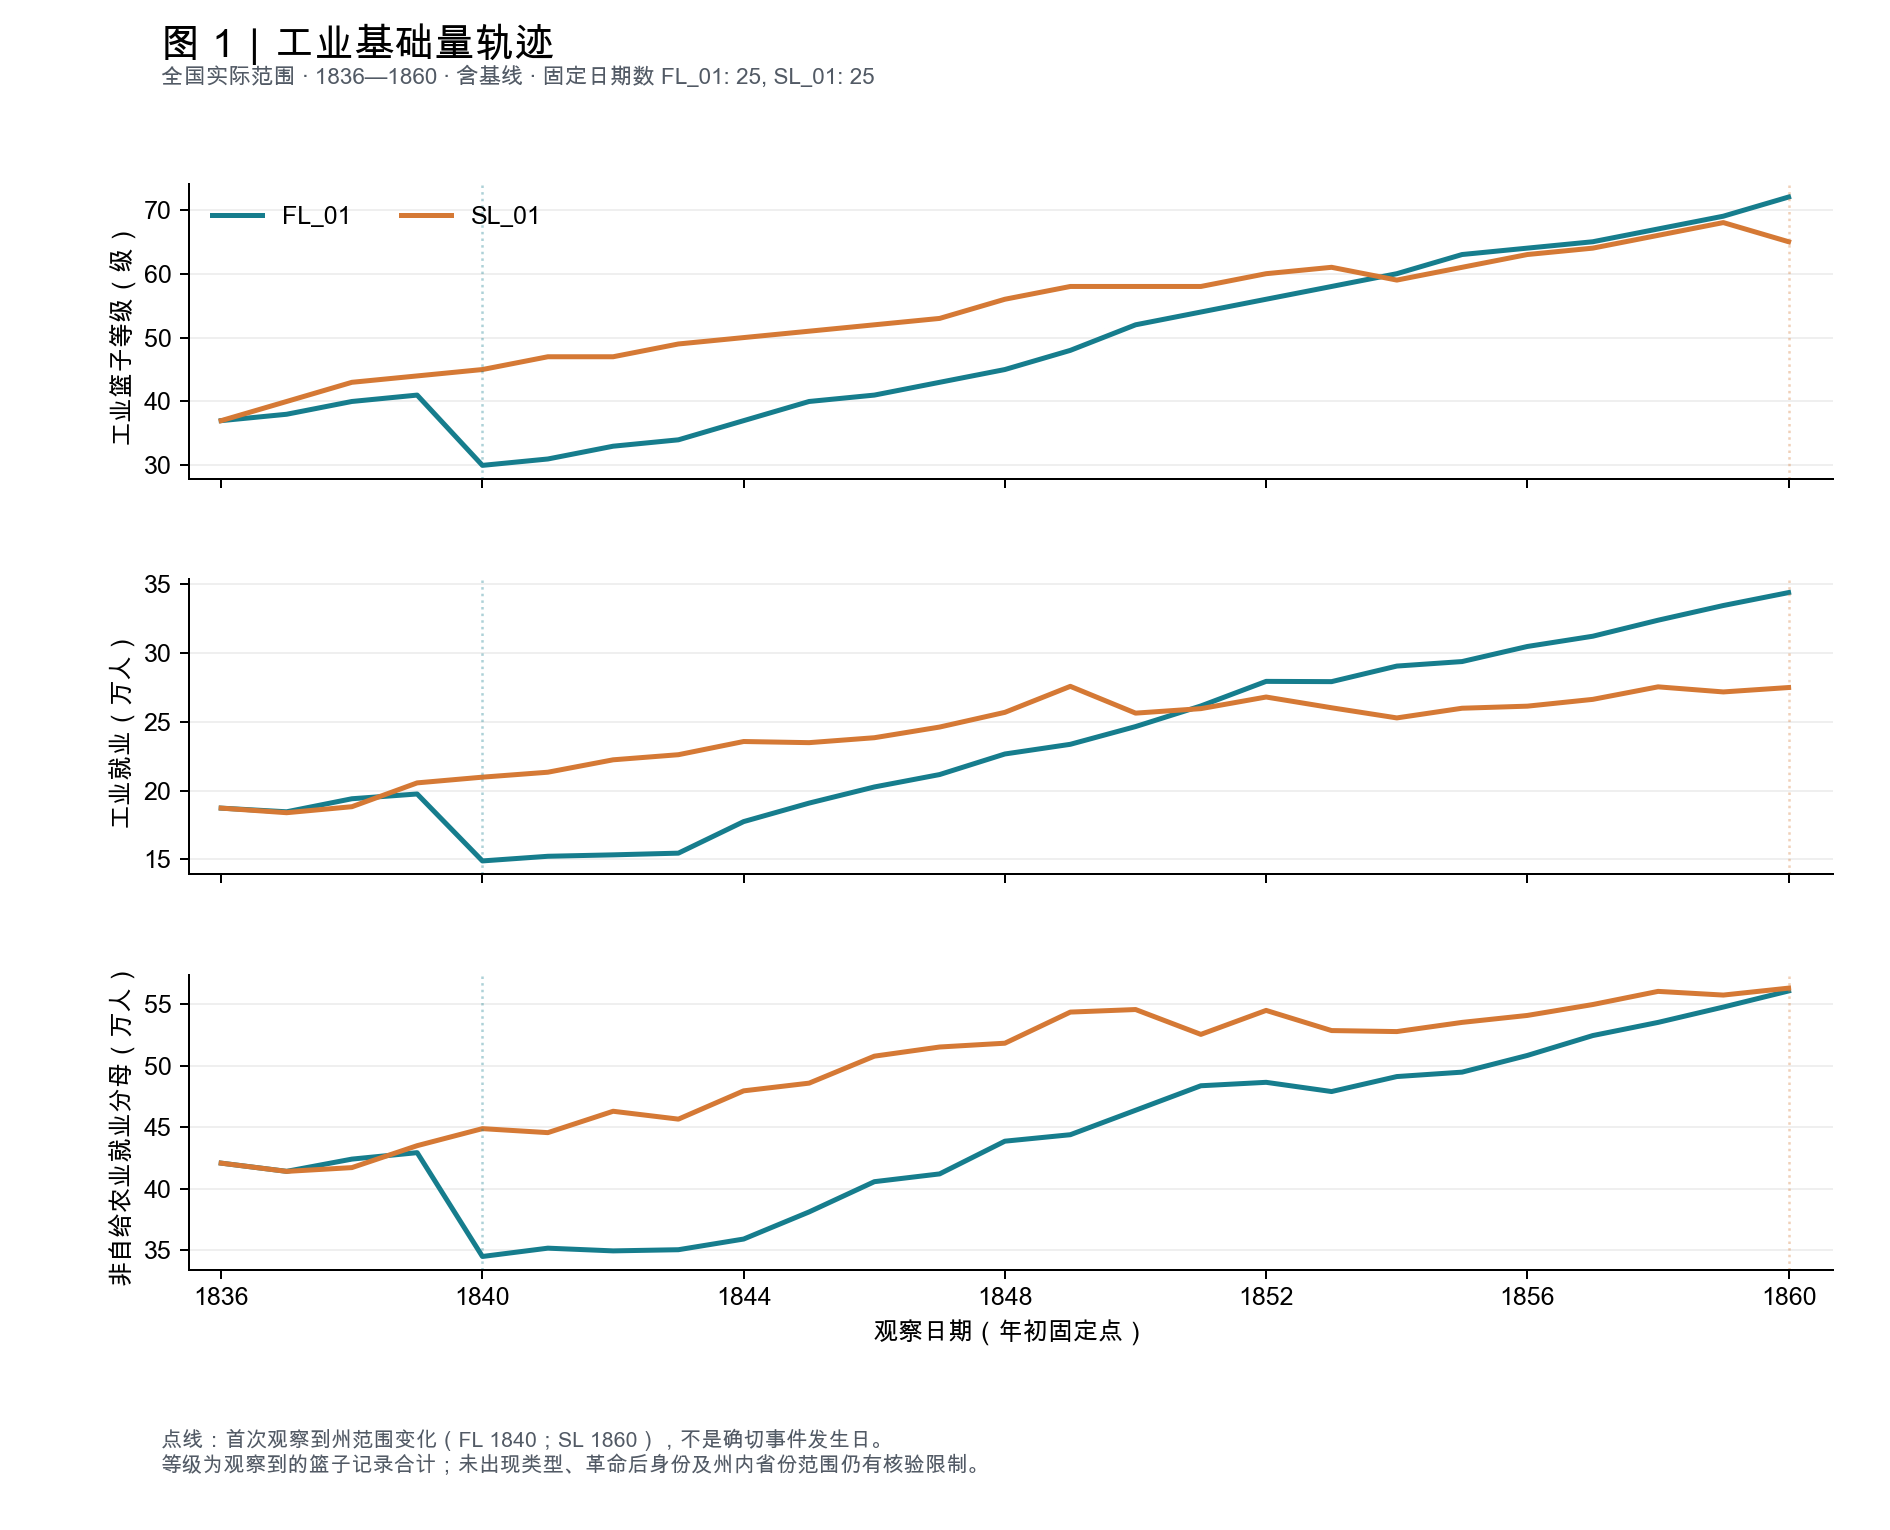

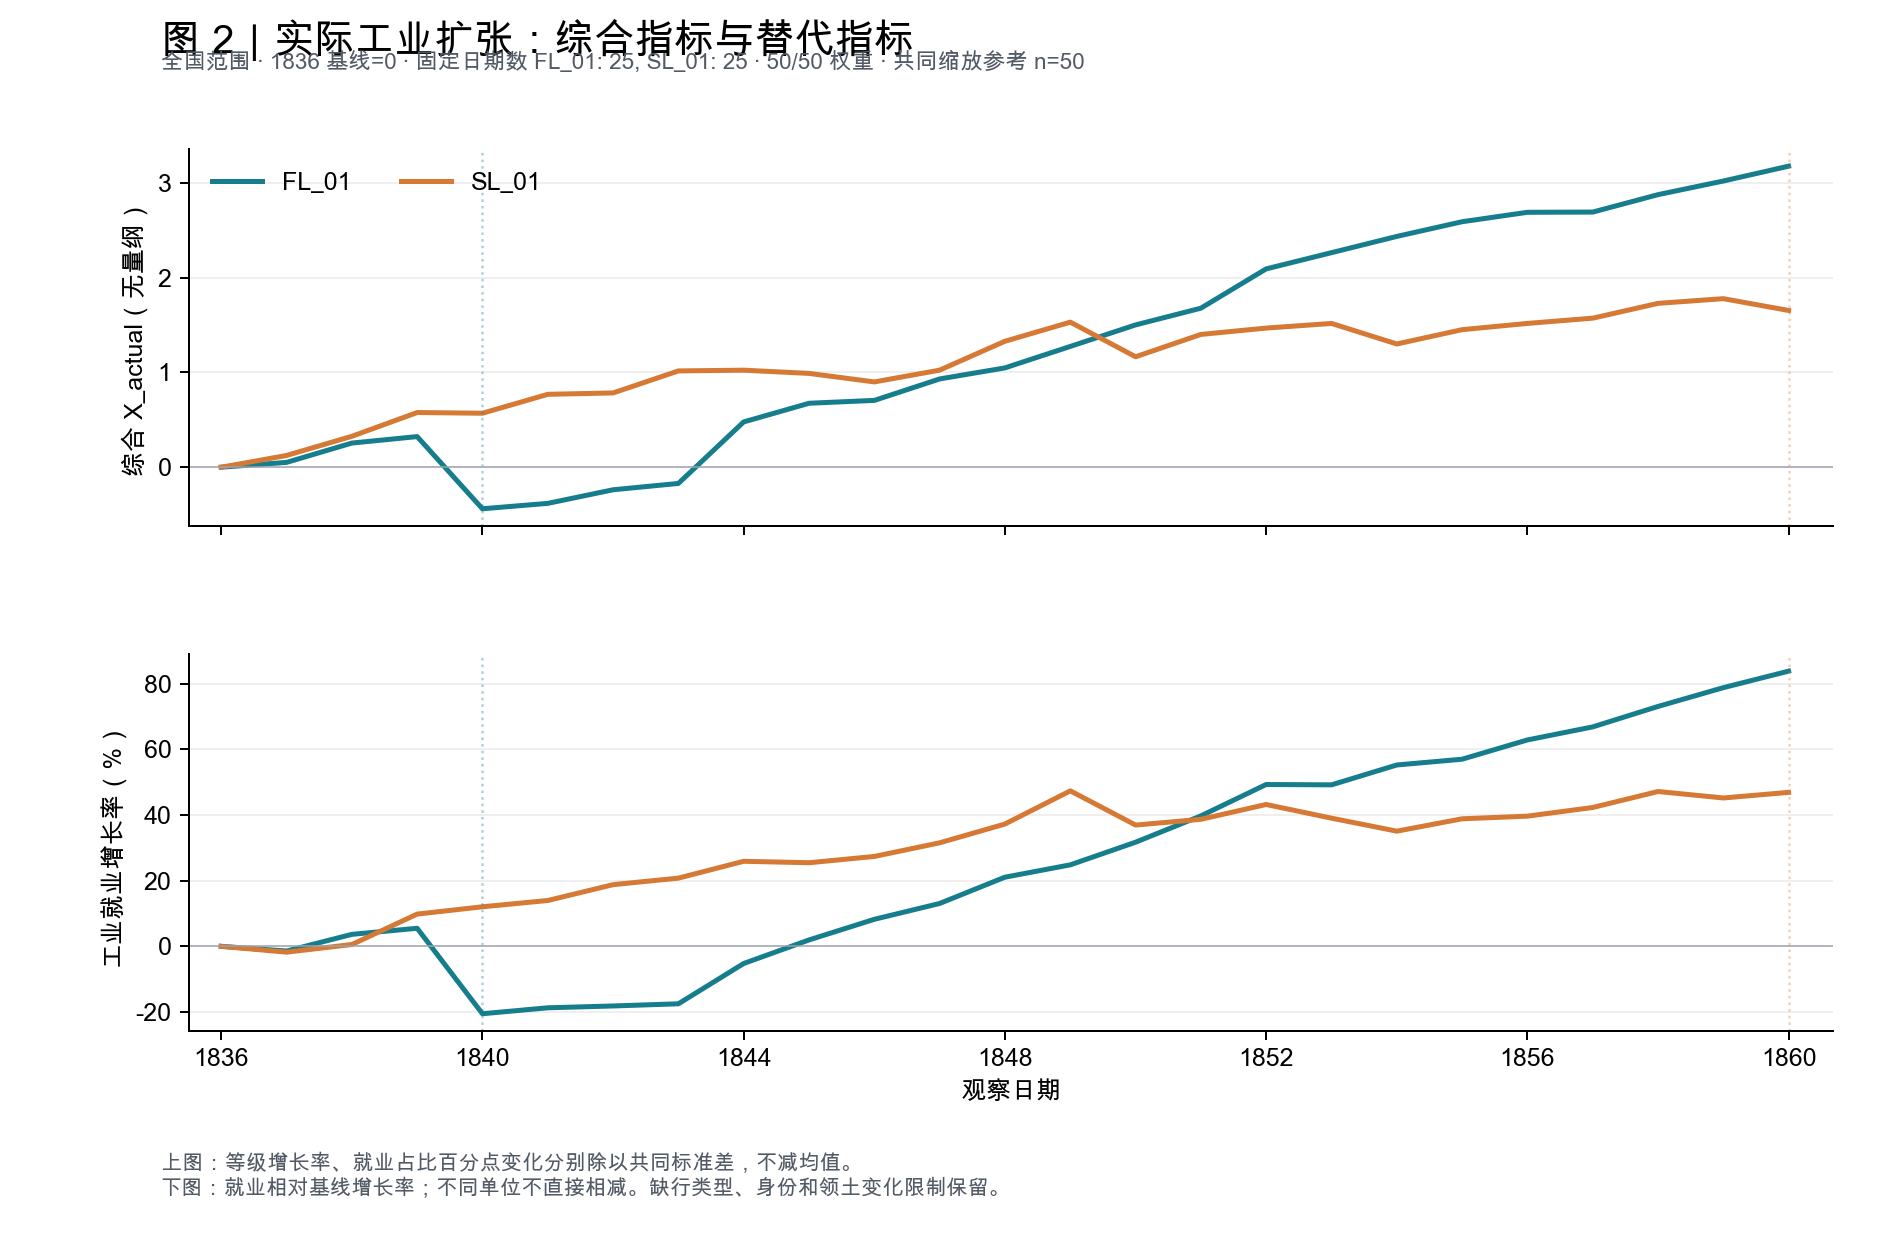

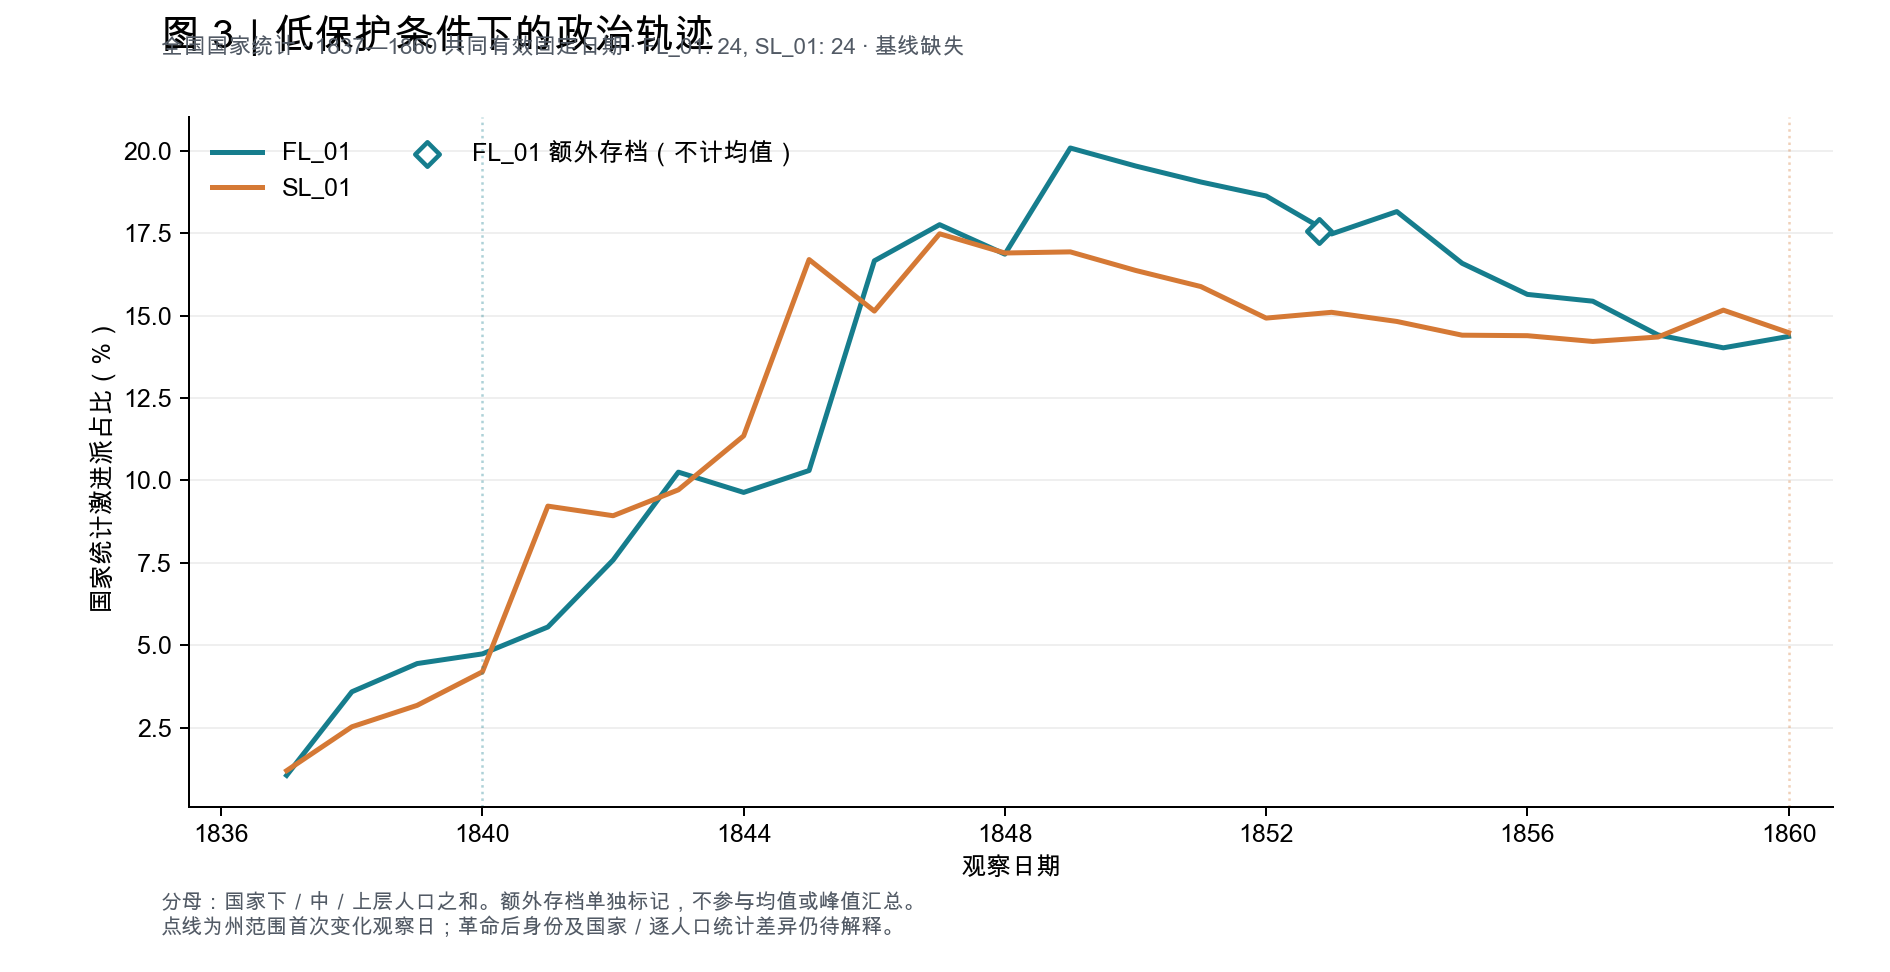

,run_id,X_actual_end,industrial_share_change_pp,Y_valid_shared_fixed_dates,Y_mean,Y_peak,Y_peak_date,Y_change_1860_minus_1837_pp
0,FL_01,3.1783,16.8445,24,0.1299,0.2008,1849-01-01,13.3136
1,SL_01,1.6549,4.3287,24,0.1240,0.1748,1847-01-01,13.2848


In [15]:
import subprocess
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

subprocess.run([sys.executable, 'scripts/part4_analysis.py', '--stage', 'figures'], check=True)
for filename in ['01_industrial_base_trends.png', '02_actual_industrialization_trends.png',
                 '03_national_radical_share_trends.png']:
    display(Image(filename=str(Path('outputs/figures') / filename)))

summary_preview = pd.read_csv('outputs/tables/run_summary.csv')
preview_columns = ['run_id', 'X_actual_end', 'industrial_share_change_pp',
                   'Y_valid_shared_fixed_dates', 'Y_mean', 'Y_peak', 'Y_peak_date',
                   'Y_change_1860_minus_1837_pp']
display(summary_preview[preview_columns].round(4))  # Y_mean/Y_peak 为0–1，变化列为百分点


## Part 5｜检查结论是否依赖口径

**80–100 分钟；操作指引 20–21。**

选一项实际重算：
- 换用 Part 1 的替代工业化指标，其他数据、条件、窗口、州范围不变；或
- 换成所选窗口内两组共同保有的州，重新筛选人口和建筑，重算分子与分母，其他规则不变。

主分析与重算结果并排保存。比较方向、幅度、转折是否改变；不同单位指标不要直接相减。国家政治人数不能随意分到共同州，州/人口政治记录未验证时只对可算的工业指标检查。共同州也不能排除全国冲击或州内省份变动。

产出：至少一项真正运行的比较图/表，两句话说明改变什么及判断是否改变。看结果后新增的分析标探索性，原结果不覆盖。代码完成这一次检查，不只写“以后可以做”。


## Part 6｜写出初步结果

**100–110 分钟；操作指引 22。**

在本格后共同写一段能进入论文的结果：
1. 引用具体图表与数值，说明观察窗口、范围、变化及不符合预期的部分。
2. 说明敏感性检查是否改变判断；把事实与可能解释分开。
3. 交代当前只有 FL、SL 各一次，以及 Y/M、革命身份等仍有哪些证据不足。未核验的指标不作正式结论。

另一人逐句检查：数字从哪张表得到？这句话是观察还是解释？当前不能检验 W 的调节作用，也不能将模型结果外推为现实社会因果关系。

产出：初步结果文字与必要方法说明。下方代码格仅用于需要的补充核对，不要求为了写文字执行代码。


## Part 7｜重跑与接入后续数据

**110–120 分钟；操作指引 23–25。**

1. 保存后 Restart Kernel & Run All，从只读原始输入重建已验证部分。没有手工改过中间 CSV，也应该能生成相同结果；待核验项明确报告，不假称全部完成。
2. 两人核对表、图和文字；按文件暂存代码、文档与审核后的汇总图表，再由学生明确发起向指定 GitHub 仓库推送。完整 data_raw/、data/processed/ 默认本地保留，老师确认分享范围后再调整；清除 Notebook 整表打印和敏感路径。不上传凭据、环境或 .v3，不擅自删除已有远程数据。
3. 程序通过目录/配置识别 run，新数据逐次执行同样的日期、身份、字段、关联检查。条件不足就提示缺组，不补假数据。新旧编号冲突先核对，不覆盖。
4. 全部数据到齐后，先统一窗口与口径、说明重复运行汇总和独立性/配对依据，再比较 FL−SL、FH−SH 及其差别，不按相同编号自动配对。

产出：重跑与提交/待推送状态；其他同伴如何取得授权输入；尚待核验的具体字段/存档、证据需求、责任人与期限。最终交付位置见 AGENTS.md，讨论仍留在本 Notebook。
